# Reduccion Imagenes

# Importación

In [1]:
import os
import warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy import units as u
from astropy.coordinates import SkyCoord
from astropy.stats import sigma_clipped_stats
from astropy.visualization import ZScaleInterval
from astropy.wcs import WCS
from scipy import ndimage
import astroalign as aa

#deteccion de objetos
from photutils.segmentation import (SourceCatalog, deblend_sources, detect_sources, detect_threshold)

#carpeta donde se guardan las figuras y los catalogos para el informe
SALIDA = 'C:/Users/marti/Test-Instr-Astro/pipeline/notebooks/resultados/REDUCCION_DETECCION_FINAL'
os.makedirs(SALIDA, exist_ok=True)

In [2]:
#abrimos las imagenes de NGC7793 en el filtro B
#se usan la 727, 729 y 731; la 728 y la 730 se descartaron en la revision de las exposiciones
b1=fits.open('NGC_7793_B_120.000secs_00000727.fit')
b2=fits.open('NGC_7793_B_120.000secs_00000728.fit') #no se usa: corrida respecto de las demas
b3=fits.open('NGC_7793_B_120.000secs_00000729.fit')
b4=fits.open('NGC_7793_B_120.000secs_00000730.fit') #no se usa
b5=fits.open('NGC_7793_B_120.000secs_00000731.fit')

In [3]:
#abrimos las imagenes de NGC7793 en el filtro V
#se usan la 723 (referencia de la alineacion) y la 725; la 724 y la 726 se descartaron
v1=fits.open('NGC_7793_V_120.000secs_00000723.fit')
v2=fits.open('NGC_7793_V_120.000secs_00000724.fit') #no se usa
v3=fits.open('NGC_7793_V_120.000secs_00000725.fit')
v4=fits.open('NGC_7793_V_120.000secs_00000726.fit') #no se usa

In [4]:
#extraemos las imagenes filtro b
datab1=b1[0].data.astype(np.float32)
datab2=b2[0].data.astype(np.float32)
datab3=b3[0].data.astype(np.float32)
datab4=b4[0].data.astype(np.float32)
datab5=b5[0].data.astype(np.float32)

#extraemos las imagenes filtro v
datav1=v1[0].data.astype(np.float32)
datav2=v2[0].data.astype(np.float32)
datav3=v3[0].data.astype(np.float32)
datav4=v4[0].data.astype(np.float32)

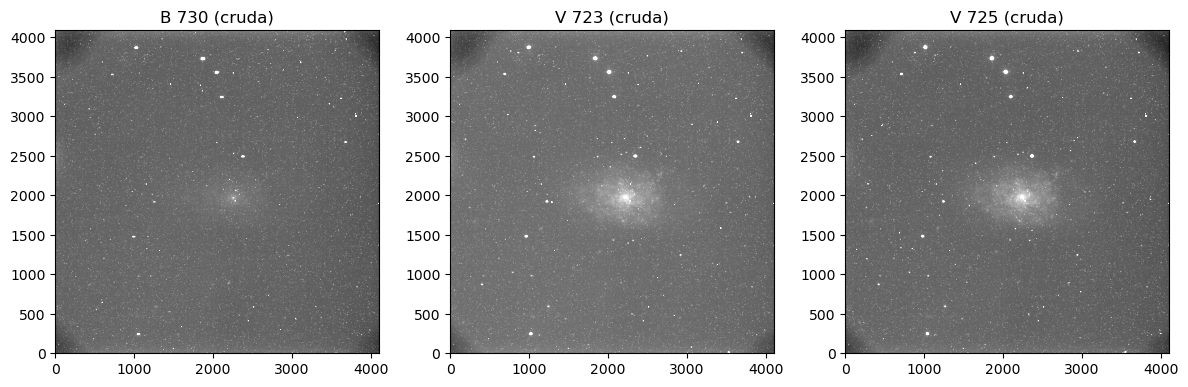

In [5]:
#graficamos algunas exposiciones crudas para revisarlas (cada una con su propia escala)
zscale=ZScaleInterval(contrast=0.25)
fig,ax=plt.subplots(1,3, figsize=(12,4))
for a,img,t in [(ax[0],datab4,'B 730 (cruda)'),(ax[1],datav1,'V 723 (cruda)'),(ax[2],datav3,'V 725 (cruda)')]:
    min_value,max_value=zscale.get_limits(img)
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

# DARKS

In [6]:
# importamos los darks de 120 s (el mismo tiempo de exposicion que la ciencia)
dark1=fits.open('Dark_120.000secs_00000774.fit')
dark2=fits.open('Dark_120.000secs_00000775.fit')
dark3=fits.open('Dark_120.000secs_00000776.fit')
dark4=fits.open('Dark_120.000secs_00000777.fit')
dark5=fits.open('Dark_120.000secs_00000778.fit')

In [7]:
#extraemos los datos de los darks
datad1=dark1[0].data.astype(np.float32)
datad2=dark2[0].data.astype(np.float32)
datad3=dark3[0].data.astype(np.float32)
datad4=dark4[0].data.astype(np.float32)
datad5=dark5[0].data.astype(np.float32)

## MASTER DARK

In [8]:
#mediana por franjas de 256 filas: con todas las imagenes completas a la vez no alcanza la memoria
def mediana_franjas(lista, paso=256):
    """Mediana pixel a pixel ignorando NaN, procesando 256 filas a la vez."""
    ny,nx=lista[0].shape
    out=np.empty((ny,nx),dtype=np.float32)
    for y in range(0,ny,paso):
        bloque=np.stack([im[y:y+paso] for im in lista])
        out[y:y+paso]=np.nanmedian(bloque,axis=0)
    return out

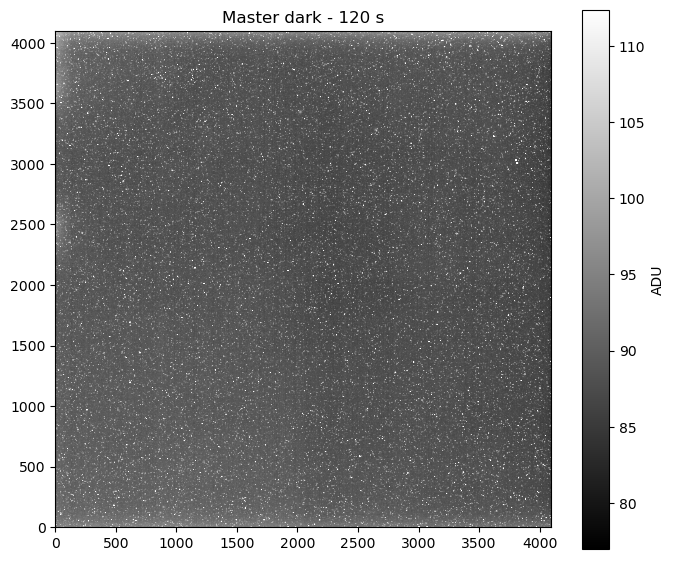

In [9]:
# creamos el master dark usando la mediana de los darks individuales
master_dark = np.nanmedian([datad1, datad2, datad3, datad4, datad5], axis=0)

zscale=ZScaleInterval(contrast=0.25)
min_value,max_value=zscale.get_limits(master_dark[np.isfinite(master_dark)])

plt.figure(figsize=(8,7))
plt.imshow(master_dark,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
plt.colorbar(label='ADU')
plt.title('Master dark - 120 s')
plt.show()

# FLATS

nivel cero: 88.0 ADU
flat B min/max:  -0.0030757400999615533 2.28747684457027
flat V min/max:  -0.003822098679638638 2.842555594162613


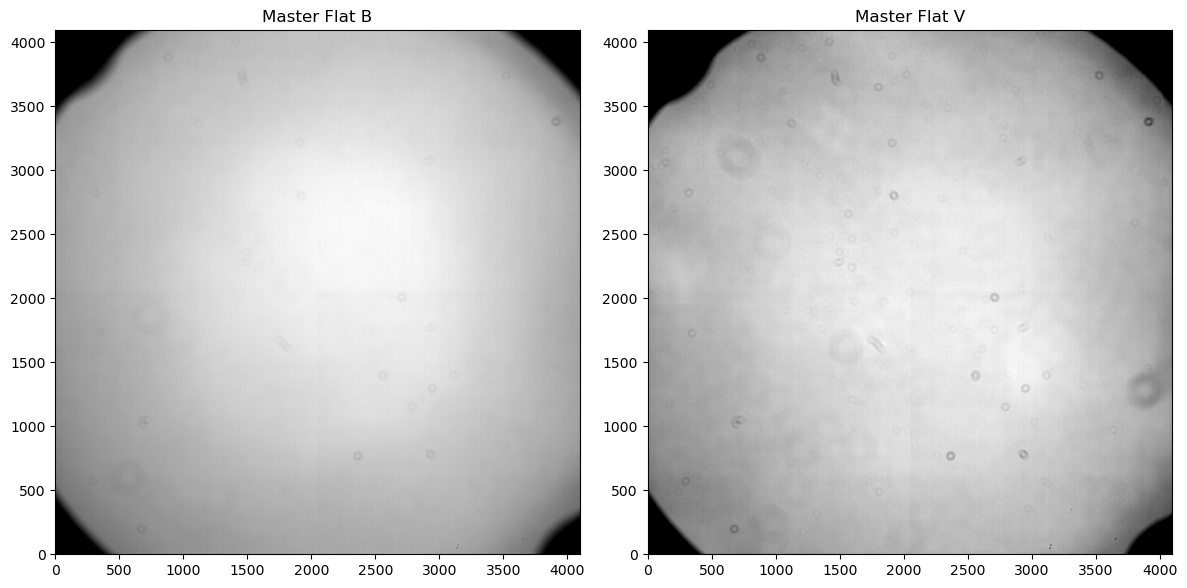

In [10]:
# extraemos los flats del filtro b
flatsB = [fits.open(f'FLAT_B_B11-{n:03}.fit')for n in range(1, 11)] #los 10 flats de cada filtro
#extraemos los flats del filtro v
flatsV = [fits.open(f'FLAT_V_B11-{n:03}.fit')for n in range(1, 11)]
#nivel cero del detector (bias): la mediana del master dark. Los flats son de 0.5 s, asi que solo se les resta
#este nivel y no el dark de 120 s (la corriente oscura de 0.5 s es despreciable)
nivel_cero = np.nanmedian(master_dark)
print('nivel cero:', nivel_cero, 'ADU')

dataflatB = np.array([f[0].data.astype(np.float64) for f in flatsB]) - nivel_cero
dataflatV = np.array([f[0].data.astype(np.float64) for f in flatsV]) - nivel_cero

#Master flat filtro V normalizado (utilizando la mediana)
master_flatv = np.nanmedian(dataflatV, axis=0)
master_flatv_norm = master_flatv / np.nanmedian(master_flatv)



#Master flat filtro b normalizado (utilizando la mediana)
master_flatb = np.nanmedian(dataflatB, axis=0)
master_flatb_norm = master_flatb / np.nanmedian(master_flatb)

print('flat B min/max: ', np.nanmin(master_flatb_norm), np.nanmax(master_flatb_norm))
print('flat V min/max: ', np.nanmin(master_flatv_norm), np.nanmax(master_flatv_norm))

fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a,f,t in [(ax[0], master_flatb_norm, 'Master Flat B'), (ax[1], master_flatv_norm, 'Master Flat V')]:
    lo, hi = ZScaleInterval(contrast=0.25).get_limits(f)
    a.imshow(f, vmin=lo, vmax=hi, cmap='gray', origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

In [11]:
bpm = fits.open('BPM.fit')
databpm=bpm[0].data

Valores BPM: (array([0, 1], dtype='>i2'), array([  632422, 16144794], dtype=int64))
Fraccion de pixeles buenos: 0.9623047113418579


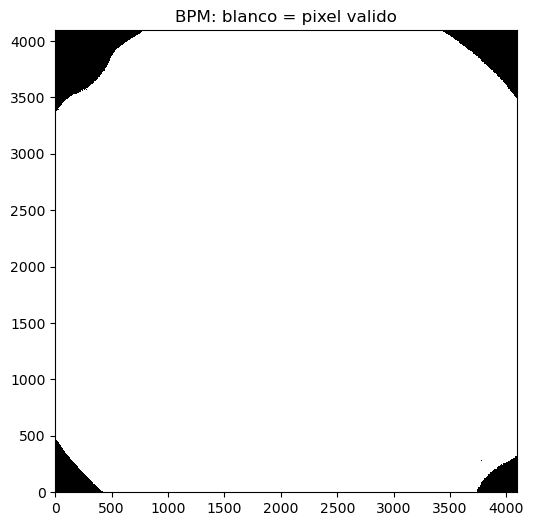

In [12]:
BPM_GOOD_VALUE=1 #en el BPM: 1 = pixel bueno, 0 = pixel malo
FLAT_MIN=0.05   #evita dividir por flats casi nulos

bpm_good=(databpm==BPM_GOOD_VALUE)
print('Valores BPM:', np.unique(databpm,return_counts=True))
print('Fraccion de pixeles buenos:', bpm_good.mean())

plt.figure(figsize=(6,6))
plt.imshow(bpm_good,cmap='gray',origin='lower',interpolation='nearest')
plt.title('BPM: blanco = pixel valido')
plt.show()

# REDUCCION

In [13]:
def reducir(data, flat_norm):
    #(cruda - master dark)/flat; los pixeles malos (BPM) y las esquinas sin luz (flat < FLAT_MIN) quedan en NaN
    valido=(bpm_good & np.isfinite(data) & np.isfinite(master_dark)
            & np.isfinite(flat_norm) & (flat_norm>FLAT_MIN))
    red=np.full(data.shape,np.nan,dtype=np.float64)
    red[valido]=(data[valido]-master_dark[valido])/flat_norm[valido]
    return red

sel_b=[datab1,datab3,datab5]   #B 727, 729 y 731
sel_v=[datav1,datav3]           #V 723 y 725

redb=[reducir(d,master_flatb_norm) for d in sel_b]
redv=[reducir(d,master_flatv_norm) for d in sel_v]

#liberamos las imagenes crudas que ya no se usan
del sel_b,sel_v,datab1,datab2,datab3,datab4,datav1,datav2,datav3,datav4

# IMAGENES REDUCIDAS Y APILADO

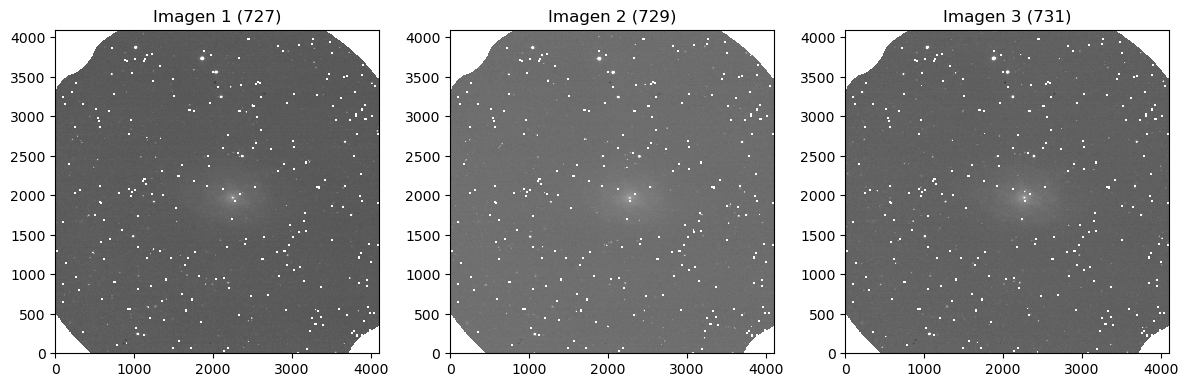

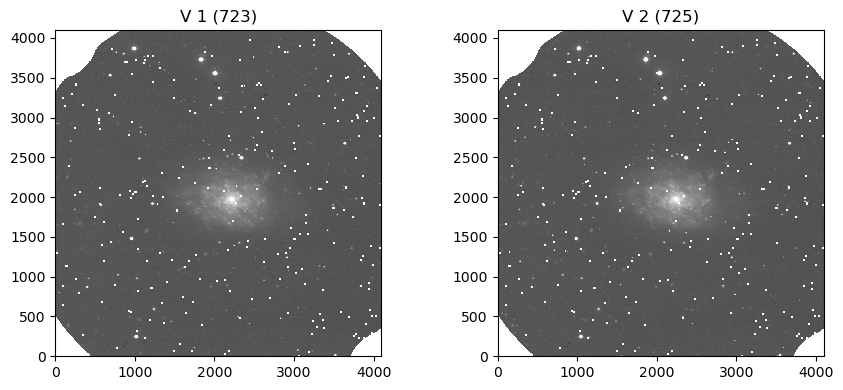

In [14]:
zscale=ZScaleInterval(contrast=0.25)

fig,ax=plt.subplots(1,3, figsize=(12,4))
titulos=['Imagen 1 (727)','Imagen 2 (729)','Imagen 3 (731)']
for a,img,t in zip(ax,redb,titulos):
    min_value,max_value=zscale.get_limits(img[np.isfinite(img)])  #limites propios de cada imagen
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

fig,ax=plt.subplots(1,2, figsize=(9,4))
titulos=['V 1 (723)','V 2 (725)']
for a,img,t in zip(ax,redv,titulos):
    min_value,max_value=zscale.get_limits(img[np.isfinite(img)])
    a.imshow(img,vmin=min_value,vmax=max_value,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

### alineación

In [15]:
def a_masked(img):
    #astroalign no tolera NaN: se rellenan con la mediana y se marcan en una mascara
    malo=~np.isfinite(img)
    return np.ma.array(np.where(malo,np.nanmedian(img),img),mask=malo)

# las estrellas se detectan aqui y se emparejan por votacion del desplazamiento (las estrellas reales se mueven
# todas igual; los rayos cosmicos y los grumos de la galaxia no). A astroalign se le entregan los pares ya
# emparejados para calcular y aplicar la transformacion (aa.find_transform solo no lograba alinear las imagenes B).
def estrellas(img, n=150):
    from photutils.detection import DAOStarFinder
    im=np.where(np.isfinite(img),img,np.nanmedian(img))
    im=im-ndimage.median_filter(im[::4,::4],25).repeat(4,0).repeat(4,1)   #quita el cielo y la galaxia
    _,med,std=sigma_clipped_stats(im[::4,::4])
    t=DAOStarFinder(fwhm=11.0,threshold=10*std,exclude_border=True)(im-med)
    t=t[(t['xcentroid']>100)&(t['xcentroid']<im.shape[1]-100)&(t['ycentroid']>100)&(t['ycentroid']<im.shape[0]-100)]
    t.sort('flux')
    t.reverse()
    return np.column_stack([t['xcentroid'],t['ycentroid']])[:n]

def emparejar(p, q, max_shift=300):
    #diferencia de posicion entre todas las parejas posibles: el desplazamiento real es el mas votado
    d=(q[None,:,:]-p[:,None,:]).reshape(-1,2)
    d=d[np.all(np.abs(d)<max_shift,axis=1)]
    h,xe,ye=np.histogram2d(d[:,0],d[:,1],bins=200,range=[[-max_shift,max_shift]]*2)
    i,j=np.unravel_index(h.argmax(),h.shape)
    dx0,dy0=(xe[i]+xe[i+1])/2,(ye[j]+ye[j+1])/2
    #pares: cada estrella de p con la de q que queda a menos de 4 px al aplicar ese desplazamiento
    dist=np.hypot(p[:,None,0]+dx0-q[None,:,0],p[:,None,1]+dy0-q[None,:,1])
    ok=dist.min(axis=1)<4
    return p[ok],q[dist.argmin(axis=1)[ok]]

def alinear(lista, ref, nombres):
    pos_ref=estrellas(ref)
    alineadas=[]
    for i,img in enumerate(lista):
        if img is ref:
            alineadas.append(img.astype(np.float32))
            print(f'{nombres[i]}: referencia')
            continue
        src,dst=emparejar(estrellas(img),pos_ref)
        if len(src)<5:
            print(f'{nombres[i]}: NO se pudo alinear (solo {len(src)} estrellas en comun); se descarta')
            continue
        T=aa.estimate_transform('euclidean',src,dst)     #desplazamiento + rotacion
        al,foot=aa.apply_transform(T,a_masked(img),a_masked(ref),fill_value=np.nan,propagate_mask=True)
        alineadas.append(np.asarray(al,dtype=np.float32))
        print(f'{nombres[i]}: shift (x,y)={T.translation.round(1)} px, '
              f'rot={np.degrees(T.rotation):.3f} deg, estrellas={len(src)}, '
              f'residuo={np.std(T(src)-dst,axis=0).round(2)} px')
    return alineadas

#el orden de estas listas debe coincidir con el orden de redb y redv
nombres_b=['727','729','731']
nombres_v=['723','725']

# B y V se alinean a la misma imagen, V 723, para que los dos filtros queden en la misma grilla de pixeles
referencia=redv[nombres_v.index('723')]
alb=alinear(redb,referencia,nombres_b)
alv=alinear(redv,referencia,nombres_v)

727: shift (x,y)=[-24.3   1.9] px, rot=-0.003 deg, estrellas=19, residuo=[0.41 0.18] px
729: shift (x,y)=[-51.7   5.2] px, rot=0.000 deg, estrellas=18, residuo=[0.4  0.22] px
731: shift (x,y)=[-45.5   1.5] px, rot=-0.007 deg, estrellas=19, residuo=[0.49 0.24] px
723: referencia
725: shift (x,y)=[-20.2  -0.7] px, rot=0.001 deg, estrellas=33, residuo=[0.46 0.26] px


C:\Users\marti\AppData\Local\Temp\ipykernel_5576\728123128.py:8: RuntimeWarning: All-NaN slice encountered
  out[y:y+paso]=np.nanmedian(bloque,axis=0)


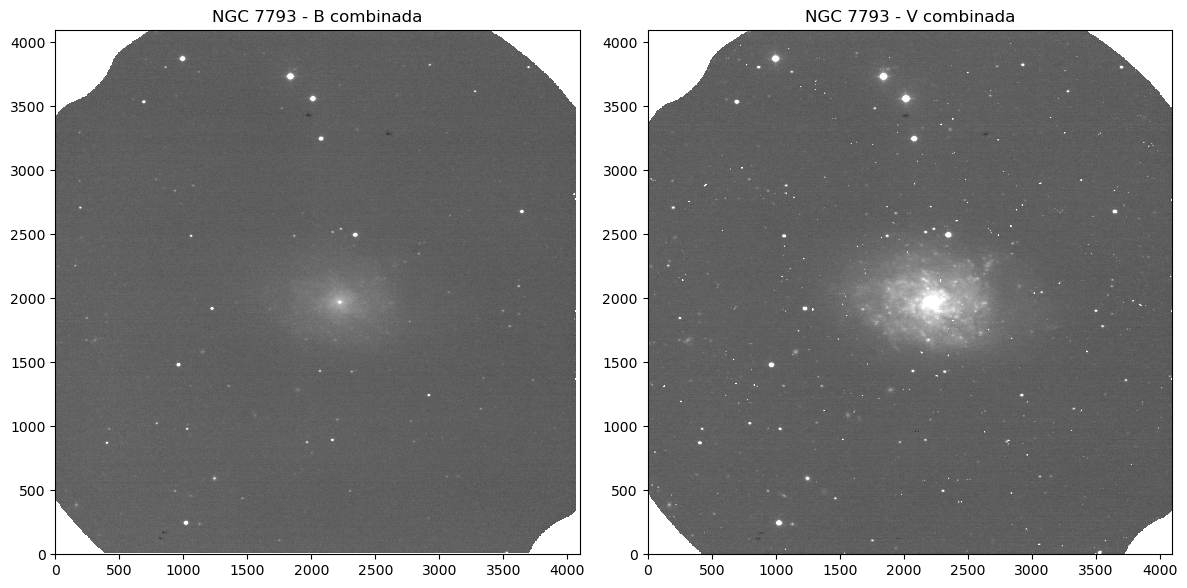

In [16]:
#graficamos ambas imagenes
final_b=mediana_franjas(alb)
final_v=mediana_franjas(alv)

fig,ax=plt.subplots(1,2,figsize=(12,6))
for a,img,t in [(ax[0],final_b,'NGC 7793 - B combinada'),(ax[1],final_v,'NGC 7793 - V combinada')]:
    lo,hi=zscale.get_limits(img[np.isfinite(img)])
    a.imshow(img,vmin=lo,vmax=hi,cmap='gray',origin='lower')
    a.set_title(t)
plt.tight_layout()
plt.show()

### Reducción paso a paso

La misma exposición (V 723) en cada etapa de la reducción, y al final el apilado de V. Arriba la imagen completa y abajo un recorte de 250 × 250 px lejos de la galaxia, donde se ven los píxeles calientes:

1. **cruda**: nivel cero del detector (~88 ADU), muchos píxeles calientes (puntos blancos del recorte) y el viñeteo (esquinas oscuras);
2. **menos el master dark**: se van el nivel cero y la corriente oscura, y con ella casi todos los píxeles calientes;
3. **dividida por el flat**: se corrige el viñeteo y la respuesta de cada píxel; las esquinas sin luz (flat < `FLAT_MIN`) y los píxeles del BPM quedan sin dato (`NaN`, en blanco);
4. **apilado**: mediana de las exposiciones alineadas. Con solo 2 exposiciones la mediana es el promedio, así que los rayos cósmicos no se eliminan, solo quedan a la mitad: son las manchas sueltas del recorte.

Cada panel tiene su propia escala de grises (ZScale).

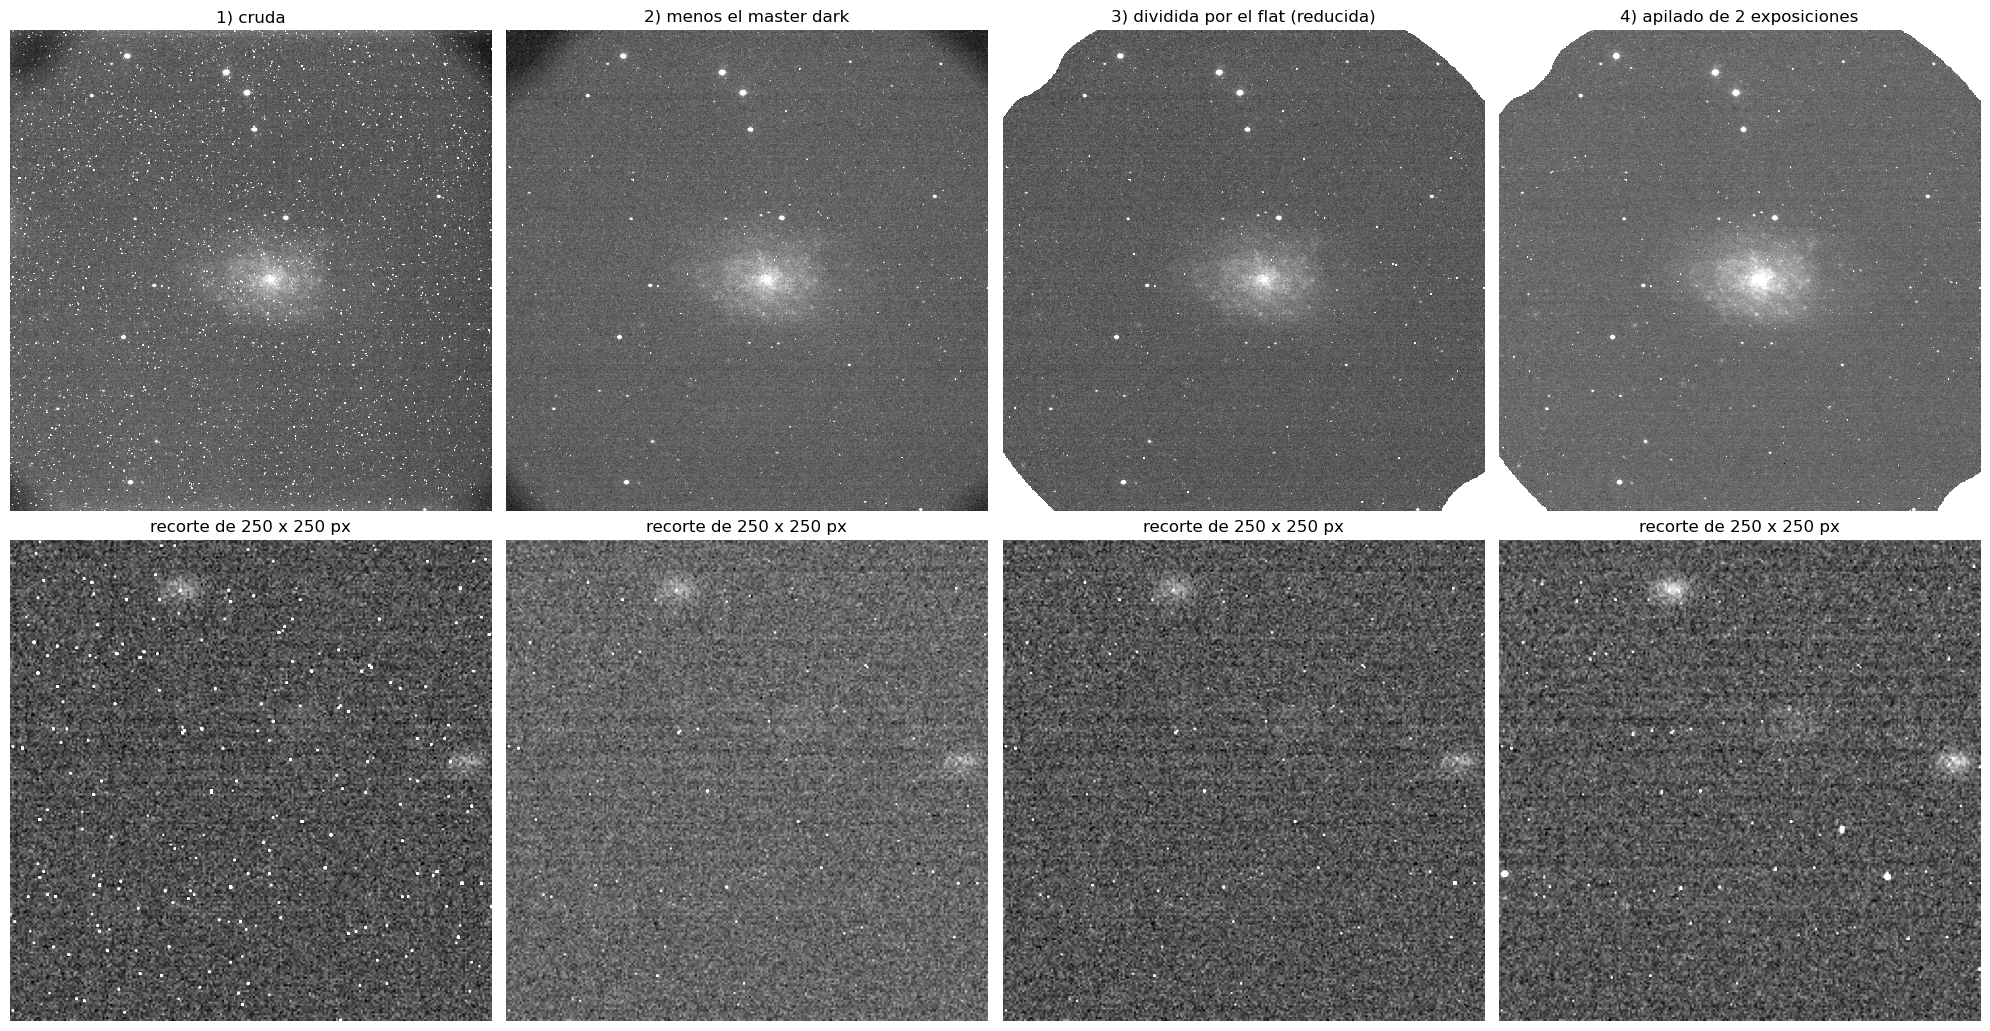

In [17]:
#REDUCCION PASO A PASO: la misma exposicion (V 723) en cada etapa, y el apilado final
cruda = v1[0].data.astype(np.float32)
pasos = [('1) cruda', cruda),
         ('2) menos el master dark', cruda - master_dark),
         ('3) dividida por el flat (reducida)', redv[0]),
         (f'4) apilado de {len(alv)} exposiciones', final_v)]
zona = (slice(2700, 2950), slice(700, 950))       #recorte lejos de la galaxia, con estrellas y pixeles calientes

fig, ax = plt.subplots(2, 4, figsize=(20, 10.5))
for k, (titulo, img) in enumerate(pasos):
    for fila, recorte in enumerate((img[::4, ::4], img[zona])):     #imagen completa (1 de cada 4 pixeles) y recorte
        lo, hi = zscale.get_limits(recorte[np.isfinite(recorte)])
        ax[fila, k].imshow(recorte, vmin=lo, vmax=hi, cmap='gray', origin='lower')
        ax[fila, k].axis('off')
    ax[0, k].set_title(titulo)
    ax[1, k].set_title('recorte de 250 x 250 px')
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'reduccion_paso_a_paso.png'), dpi=100)
plt.show()
del cruda, pasos

# FITS - ASTROMETRÍA

In [18]:
#Creación fits y astrometría

# WCS.to_header() tambien devuelve la fecha y el lugar de la observacion (DATE-OBS, MJD-OBS, MJDREF, OBSGEO-*).
# Esas claves no son de la solucion astrometrica: no se copian de un header a otro (wcs_15oct.fits trae la fecha de
# V 723, que pisaria la de B) ni se borran al cambiar el WCS.
CLAVES_NO_WCS = ('DATE', 'MJD', 'OBSGEO', 'TIME', 'TSTART', 'TSTOP', 'XPOSURE', 'TELAPSE')
def solo_wcs(header):
    h = WCS(header).to_header(relax=True)
    for k in [k for k in h if k.startswith(CLAVES_NO_WCS)]:
        del h[k]
    return h

phdu = fits.PrimaryHDU(header = b1[0].header , data = final_b)
phdu.data = np.float32(phdu.data)

# WCS de partida: la solucion de astrometry.net (wcs_15oct.fits), resuelta sobre la grilla de V 723, que es la
# de las dos imagenes. Si no esta, un WCS aproximado con el centro del header (OBJCTRA/OBJCTDEC, que el 15/10
# quedo ~40' corrido). La calibracion final se hace con Gaia en la seccion siguiente.
phdu.header['PIXSCALE'] = 0.317
if os.path.exists('wcs_15oct.fits'):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        phdu.header.update(solo_wcs(fits.getheader('wcs_15oct.fits')))
else:
    #sin la solucion de astrometry.net: WCS aproximado (el centro del header puede quedar corrido ~40')
    print('No esta wcs_15oct.fits: WCS aproximado con el centro del header')
    phdu.header['CTYPE1'] = 'RA---TAN'
    phdu.header['CTYPE2'] = 'DEC--TAN'
    phdu.header['CRPIX1'] = int(phdu.header['NAXIS1']/2)
    phdu.header['CRPIX2'] = int(phdu.header['NAXIS2']/2)

    coord = SkyCoord(f"{phdu.header['OBJCTRA']} {phdu.header['OBJCTDEC']}", unit=(u.hourangle, u.deg))#Transformacion de unidades a grados decimales

    phdu.header['CRVAL1'] = coord.ra.value
    phdu.header['CRVAL2'] = coord.dec.value
    phdu.header['CD1_1'] = 0.317/3600   #positivo: la imagen esta espejada (el este queda a la derecha)
    phdu.header['CD1_2'] = 0
    phdu.header['CD2_1'] = 0
    phdu.header['CD2_2'] = 0.317/3600
phdu.header['OBSERVER'] = 'Bustos, Medina, Oyarzo'

phdu.writeto('Img_B.fits', overwrite = True)

# se guarda V con el mismo WCS que B (las dos estan en la grilla de V 723)
hdu_v = fits.PrimaryHDU(header=v1[0].header, data=np.float32(final_v))
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    hdu_v.header.update(solo_wcs(phdu.header))   #WCS completo (PC/CDELT o CD, segun la solucion), sin la fecha de B
hdu_v.header['PIXSCALE'] = phdu.header['PIXSCALE']
hdu_v.header['OBSERVER'] = phdu.header['OBSERVER']
hdu_v.writeto('Img_V.fits', overwrite=True)

### Calibración astrométrica con Gaia

La solución de astrometry.net (`wcs_15oct.fits`, resuelta sobre la grilla de V 723) sirve como punto de partida, pero trae términos de distorsión (SIP) que en este campo empeoran la astrometría. La calibración final se hace con Gaia DR3:

1. se descargan de VizieR las estrellas de Gaia DR3 del campo (G < 17) y sus posiciones se llevan a la fecha de la observación con el movimiento propio;
2. las estrellas más brillantes de la imagen V (centro de una gaussiana 2D) se emparejan con Gaia usando el WCS de astrometry.net;
3. con esas parejas se ajusta un WCS nuevo (proyección TAN: escala, rotación y centro) con `fit_wcs_from_points`;
4. se comparan los residuos (imagen − Gaia) de las dos soluciones y se graba la de Gaia en `Img_V.fits` e `Img_B.fits`, que están en la misma grilla.

Gaia se descarga la primera vez y queda guardado en `gaia_ngc7793.ecsv`.

Set OBSGEO-Y to -5196255.928 from OBSGEO-[LBH].
Set OBSGEO-Z to -3215219.022 from OBSGEO-[LBH]'. [astropy.wcs.wcs]


100 estrellas de Gaia (G < 17) | 54 estrellas de la imagen | 41 con pareja a < 3"
astrometry.net  : escala 0.3162 "/px, rotacion -1.50 grados, residuo rms 0.72", maximo 1.81"
ajuste con Gaia : escala 0.3163 "/px, rotacion -1.52 grados, residuo rms 0.09", maximo 0.45"


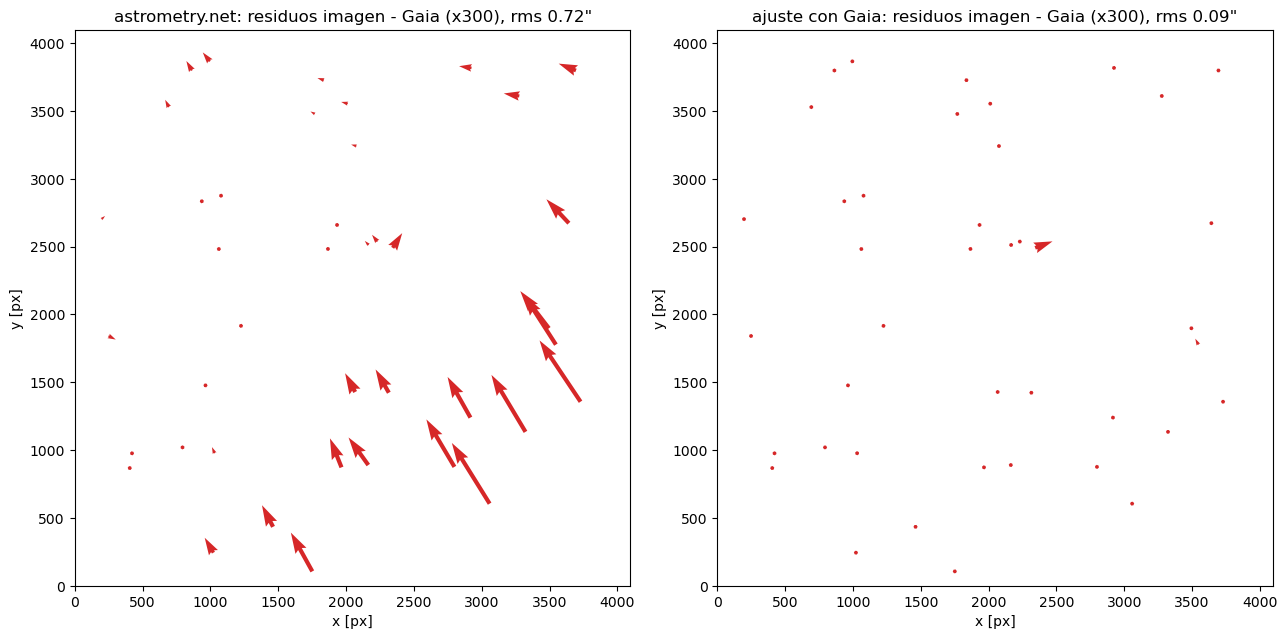

In [19]:
# calibracion astrometrica: astrometry.net como punto de partida, ajuste final con Gaia DR3
import urllib.request
from astropy.time import Time
from astropy.table import Table
from astropy.wcs.utils import fit_wcs_from_points, proj_plane_pixel_scales
from scipy.optimize import curve_fit

FWHM_INI = 12.0      # px, seeing ~3.8" (solo para empezar el ajuste de las estrellas)

def gauss2d(xy, amp, x0, y0, sx, sy, th, fondo):
    #gaussiana 2D eliptica y rotada, sobre un fondo constante
    x, y = xy
    a = np.cos(th)**2/(2*sx**2) + np.sin(th)**2/(2*sy**2)
    b = np.sin(2*th)*(1/(4*sy**2) - 1/(4*sx**2))
    c = np.sin(th)**2/(2*sx**2) + np.cos(th)**2/(2*sy**2)
    return fondo + amp*np.exp(-(a*(x-x0)**2 + 2*b*(x-x0)*(y-y0) + c*(y-y0)**2))

def ajustar_estrellas(img, n=80, r=20, pico_max=40000):
    #centro (x, y), FWHM (px) y elipticidad de las estrellas aisladas y no saturadas
    pos = estrellas(img, n)      #funcion de la seccion de alineamiento (las n mas brillantes)
    if len(pos) == 0:
        return np.empty((0, 2)), np.array([]), np.array([])
    dist = np.hypot(pos[:, None, 0]-pos[None, :, 0], pos[:, None, 1]-pos[None, :, 1])
    np.fill_diagonal(dist, np.inf)
    aisladas = pos[dist.min(axis=1) > 2*r]
    yy, xx = np.mgrid[-r:r+1, -r:r+1]
    xy, fwhm, elip = [], [], []
    for x, y in aisladas:
        xi, yi = int(round(x)), int(round(y))
        rec = img[yi-r:yi+r+1, xi-r:xi+r+1]
        if rec.shape != xx.shape or not np.all(np.isfinite(rec)) or rec.max() > pico_max:
            continue                 #en el borde, con pixeles sin dato o saturada
        fondo = np.median(rec)
        p0 = [rec.max()-fondo, 0, 0, FWHM_INI/2.355, FWHM_INI/2.355, 0, fondo]
        try:
            p, _ = curve_fit(gauss2d, (xx.ravel(), yy.ravel()), rec.ravel(), p0=p0, maxfev=3000)
        except (RuntimeError, ValueError):
            continue
        amp, x0, y0, sx, sy = p[0], p[1], p[2], abs(p[3]), abs(p[4])
        f = 2.355*np.sqrt(sx*sy)
        if amp <= 0 or abs(x0) > 3 or abs(y0) > 3 or not 3 < f < 40:
            continue                 #ajuste que no corresponde a una estrella
        xy.append((xi+x0, yi+y0))
        fwhm.append(f)
        elip.append(1 - min(sx, sy)/max(sx, sy))
    return np.array(xy).reshape(-1, 2), np.array(fwhm), np.array(elip)

def gaia_dr3(centro, radio_arcmin=16, gmax=17):
    #estrellas de Gaia DR3 (VizieR, catalogo I/355) alrededor de centro, con G < gmax
    consulta = (f"/viz-bin/asu-tsv?-source=I/355/gaiadr3&-c={centro.ra.deg:.5f}{centro.dec.deg:+.5f}"
                f"&-c.rm={radio_arcmin}&-out=RA_ICRS,DE_ICRS,pmRA,pmDE,Gmag&Gmag=%3C{gmax}&-out.max=5000")
    for servidor in ('https://vizier.cds.unistra.fr', 'https://vizier.cfa.harvard.edu'):   #dos espejos de VizieR
        try:
            texto = urllib.request.urlopen(servidor + consulta, timeout=60).read().decode()
        except OSError as e:
            print(f'{servidor} no responde ({e})')
            continue
        filas = [l.split('\t') for l in texto.splitlines() if l and not l.startswith('#')][3:]   #salta 3 lineas de encabezado
        if filas:
            break
        print(f'{servidor} no devolvio estrellas')
    else:
        raise RuntimeError(f'No se pudo descargar Gaia (sin internet?). Copiar {ARCHIVO_GAIA} junto al notebook')
    num = lambda s: float(s) if s.strip() else 0.0                                             #movimiento propio vacio = 0
    return Table(rows=[[num(v) for v in f] for f in filas], names=('ra', 'dec', 'pmra', 'pmdec', 'G'))

def resumen_wcs(w):
    #escala ("/px) y rotacion (grados) de un WCS
    cd = w.pixel_scale_matrix
    return proj_plane_pixel_scales(w).mean()*3600, np.degrees(np.arctan2(cd[1, 0], cd[1, 1]))

ARCHIVO_GAIA = 'gaia_ngc7793.ecsv'      # se guarda la descarga para no repetirla
#memmap=False: se lee a memoria y el archivo queda cerrado (en Windows, si queda abierto, no se puede grabar el WCS nuevo)
imgV = fits.getdata('Img_V.fits', memmap=False)   # apilado V con el WCS de astrometry.net (grabado arriba)
hdrV = fits.getheader('Img_V.fits')
wcs_anet = WCS(hdrV)
centro = wcs_anet.pixel_to_world(imgV.shape[1]/2, imgV.shape[0]/2)
if os.path.exists(ARCHIVO_GAIA):
    gaia = Table.read(ARCHIVO_GAIA)
else:
    gaia = gaia_dr3(centro)
    gaia.write(ARCHIVO_GAIA, overwrite=True)

#posiciones de Gaia (epoca 2016.0) llevadas a la fecha de la observacion con el movimiento propio
dt = Time(hdrV['DATE-OBS']).decimalyear - 2016.0
c_gaia = SkyCoord(gaia['ra'] + gaia['pmra']/3.6e6*dt/np.cos(np.radians(gaia['dec'])),
                  gaia['dec'] + gaia['pmdec']/3.6e6*dt, unit='deg')

#estrellas de la imagen (centro de una gaussiana 2D) y su pareja en Gaia con el WCS de partida
pos, _, _ = ajustar_estrellas(imgV, n=150)
idx_g, sep, _ = wcs_anet.pixel_to_world(pos[:, 0], pos[:, 1]).match_to_catalog_sky(c_gaia)
par = sep < 3*u.arcsec                   #pareja a menos de 3" (~10 px)
xy = (pos[par, 0], pos[par, 1])
c_par = c_gaia[idx_g[par]]
print(f'{len(gaia)} estrellas de Gaia (G < 17) | {len(pos)} estrellas de la imagen | {par.sum()} con pareja a < 3"')

#WCS nuevo ajustado solo con las parejas de Gaia (proyeccion TAN lineal: escala, rotacion y centro)
wcs_gaia = fit_wcs_from_points(xy, c_par, projection='TAN')

def residuos(w):
    #diferencia imagen - Gaia en arcsec (RA cos Dec, Dec)
    c = w.pixel_to_world(*xy)
    return ((c.ra - c_par.ra)*np.cos(c_par.dec.radian)).to(u.arcsec).value, (c.dec - c_par.dec).to(u.arcsec).value

for nombre, w in (('astrometry.net', wcs_anet), ('ajuste con Gaia', wcs_gaia)):
    dra, ddec = residuos(w)
    escala, rot = resumen_wcs(w)
    print(f'{nombre:16s}: escala {escala:.4f} "/px, rotacion {rot:+.2f} grados, '
          f'residuo rms {np.sqrt(np.mean(dra**2 + ddec**2)):.2f}", maximo {np.hypot(dra, ddec).max():.2f}"')

#figura: residuos en el campo con cada WCS (flechas aumentadas 300 veces)
fig, ax = plt.subplots(1, 2, figsize=(13, 6.5))
for a, (nombre, w) in zip(ax, (('astrometry.net', wcs_anet), ('ajuste con Gaia', wcs_gaia))):
    dra, ddec = residuos(w)
    a.quiver(*xy, dra, ddec, angles='xy', scale_units='xy', scale=1/300, color='C3')
    a.set(xlim=(0, imgV.shape[1]), ylim=(0, imgV.shape[0]), aspect='equal', xlabel='x [px]', ylabel='y [px]',
          title=f'{nombre}: residuos imagen - Gaia (x300), rms {np.sqrt(np.mean(dra**2 + ddec**2)):.2f}"')
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'astrometria_gaia.png'), dpi=120)
plt.show()

In [20]:
# se graba el WCS ajustado con Gaia en Img_V.fits e Img_B.fits (las dos estan en la misma grilla, la de V 723)
def cambiar_wcs(archivo, w):
    with fits.open(archivo, mode='update') as hdul, warnings.catch_warnings():
        warnings.simplefilter('ignore')          #avisos de astropy sobre claves del header (OBSGEO)
        h = hdul[0].header
        #se borra el WCS anterior, incluidos los terminos de distorsion SIP de astrometry.net.
        #se conservan la fecha y el lugar de la observacion (CLAVES_NO_WCS, celda de creacion de los fits)
        viejas = (list(solo_wcs(h).keys())
                  + [k for k in h if k.startswith(('A_', 'B_', 'AP_', 'BP_'))])
        for k in viejas:
            h.remove(k, ignore_missing=True, remove_all=True)
        h.update(w.to_header(relax=True))
        h['PIXSCALE'] = (round(resumen_wcs(w)[0], 4), '[arcsec/px] ajuste con Gaia DR3')
        h['WCSSRC'] = ('Gaia DR3', f'WCS ajustado con {par.sum()} estrellas')

for archivo in ('Img_V.fits', 'Img_B.fits'):
    cambiar_wcs(archivo, wcs_gaia)
    print(f"{archivo}: DATE-OBS = {fits.getheader(archivo).get('DATE-OBS')}")

#comprobacion en B con sus propias estrellas
imgB = fits.getdata('Img_B.fits', memmap=False)
posB, _, _ = ajustar_estrellas(imgB, n=150)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    cB = WCS(fits.getheader('Img_B.fits')).pixel_to_world(posB[:, 0], posB[:, 1])
_, sepB, _ = cB.match_to_catalog_sky(c_gaia)
okB = sepB < 3*u.arcsec
print(f'B con el WCS nuevo: {okB.sum()} estrellas con pareja en Gaia, residuo rms {np.sqrt(np.mean(sepB[okB].arcsec**2)):.2f}"')

Img_V.fits: DATE-OBS = 2026-10-16T01:46:46.101
Img_B.fits: DATE-OBS = 2026-10-16T01:56:20.370
B con el WCS nuevo: 32 estrellas con pareja en Gaia, residuo rms 0.13"


# REDUCCION ESTRELLAS ESTÁNDAR

Las estándares HD 220881 (archivos `HIP_115796`) y HD 8130 (`HIP_6257`) se observaron el 26/10 con tiempos de 5 a 70 s, así que no sirve el master dark de 120 s:

- **nivel cero**: mediana de los darks de 5 s (bias + 5 s de corriente oscura, que es despreciable);
- **corriente oscura**: promedio de (dark − nivel cero) / t con los darks de 40 y 70 s, en ADU/s, escalada al tiempo de cada exposición;
- **archivos**: los de `Estrellas_estandar_data` tienen que estar en la misma carpeta que el notebook (o cambiar `DIR_STD`);
- **flats**: los mismos del 15/10 que usa la ciencia (el 26/10 no se tomaron);
- **sin BPM**: en una sola exposición no hay otra que rellene el hueco, y un píxel enmascarado dentro de la apertura le quita flujo a la estrella.

En cada exposición se ubica la estándar (la estrella más brillante), se ajusta una gaussiana 2D para tener el centro y el FWHM, y se mide el flujo en una apertura de 3 FWHM, restando el cielo de un anillo entre 3,5 y 5 FWHM. Entonces

$$ZP = m_\mathrm{std} + 2{,}5\log_{10} F\,[\mathrm{ADU/s}] + kX$$

En V el ZP es el promedio de las exposiciones. En B se ajusta además el término de color con las dos estrellas, $ZP_B = ZP_0 + c\,(B-V)$: $ZP_0$ es el ZP para $B - V = 0$ y $c$ se usa en la sección del término de color.

In [21]:
# datos de las estrellas estandar del 26/10
import glob
from astropy.table import Table
from scipy.optimize import least_squares
from photutils.aperture import CircularAperture, CircularAnnulus, aperture_photometry

DIR_STD = '.'     # carpeta con los archivos de Estrellas_estandar_data ('.' si estan junto al notebook)
#magnitudes Johnson de Mermilliod (catalogo II/168)
ESTANDARES = [{'nombre': 'HD 220881', 'archivos': 'HIP_115796', 'B': 7.720, 'V': 7.440},   # A9V
              {'nombre': 'HD 8130',   'archivos': 'HIP_6257',   'B': 7.493, 'V': 7.448}]   # A0V
K_EXT = {'V': 0.15, 'B': 0.25}    # extincion en mag por masa de aire (valores tipicos de Cerro Tololo)
SATURACION = 60000                # ADU crudos: limite de linealidad que se usa (el convertidor llega a 65535)

def leer(patron):
    archivos = sorted(glob.glob(os.path.join(DIR_STD, patron)))
    if not archivos:
        raise FileNotFoundError(f'No hay archivos {patron} en {os.path.abspath(DIR_STD)}')
    return archivos

#nivel cero: mediana de los darks de 5 s
cero_std = np.nanmedian([fits.getdata(f).astype(np.float32) for f in leer('Dark_5.000secs_*.fit')], axis=0)

#corriente oscura (ADU/s): promedio de (dark - nivel cero)/t con los darks de 40 y 70 s
darks_largos = leer('Dark_40.000secs_*.fit') + leer('Dark_70.000secs_*.fit')
dc_std = np.zeros_like(cero_std)
for f in darks_largos:
    dc_std += (fits.getdata(f).astype(np.float32) - cero_std) / fits.getheader(f)['EXPTIME']
dc_std /= len(darks_largos)

print(f'nivel cero {np.nanmedian(cero_std):.0f} ADU, corriente oscura mediana {np.nanmedian(dc_std):.4f} ADU/s '
      f'({len(darks_largos)} darks de 40 y 70 s)')

nivel cero 87 ADU, corriente oscura mediana 0.0093 ADU/s (10 darks de 40 y 70 s)


In [22]:
# fotometria de la estandar
FWHM_SIGMA = 2.3548    # FWHM = 2.3548 sigma

def gauss2d_std(p, y, x):
    #gaussiana 2D eliptica y rotada + fondo constante
    amp, x0, y0, sx, sy, theta, fondo = p
    ct, st = np.cos(theta), np.sin(theta)
    xr = (x - x0)*ct + (y - y0)*st
    yr = -(x - x0)*st + (y - y0)*ct
    return fondo + amp*np.exp(-0.5*((xr/sx)**2 + (yr/sy)**2))

def medir_estandar(red, fwhm_ini=11.0, factor=3.0):
    #posicion: maximo de la imagen suavizada (asi no gana un rayo cosmico)
    lleno = np.where(np.isfinite(red), red, np.nanmedian(red))
    yi, xi = np.unravel_index(np.argmax(ndimage.gaussian_filter(lleno, fwhm_ini/FWHM_SIGMA)), red.shape)
    #centro y FWHM: gaussiana 2D ajustada a un recorte de +-3 FWHM
    m = int(3*fwhm_ini)
    y0, x0 = max(yi - m, 0), max(xi - m, 0)
    rec = lleno[y0:yi + m + 1, x0:xi + m + 1]
    yy, xx = np.mgrid[:rec.shape[0], :rec.shape[1]]
    fondo0 = np.median(np.concatenate([rec[0], rec[-1]]))
    s0 = fwhm_ini/FWHM_SIGMA
    p0 = [rec.max() - fondo0, xi - x0, yi - y0, s0, s0, 0.0, fondo0]
    lim = ([0, 0, 0, 0.3, 0.3, -np.pi, -np.inf], [np.inf, rec.shape[1] - 1, rec.shape[0] - 1, rec.shape[1], rec.shape[0], np.pi, np.inf])
    ajuste = least_squares(lambda p: (gauss2d_std(p, yy, xx) - rec).ravel(), p0, bounds=lim, max_nfev=200)
    if ajuste.success:
        x, y, fwhm = x0 + ajuste.x[1], y0 + ajuste.x[2], FWHM_SIGMA*np.sqrt(ajuste.x[3]*ajuste.x[4])
    else:
        x, y, fwhm = float(xi), float(yi), fwhm_ini
    #flujo: apertura de 3 FWHM (>99 % del flujo de una gaussiana) menos el cielo del anillo de 3.5 a 5 FWHM
    ap = CircularAperture((x, y), r=factor*fwhm)
    anillo = CircularAnnulus((x, y), r_in=(factor + 0.5)*fwhm, r_out=(factor + 2.0)*fwhm)
    suma = float(aperture_photometry(red, ap, mask=~np.isfinite(red))['aperture_sum'][0])
    vals = anillo.to_mask(method='center').get_values(red)
    _, cielo, _ = sigma_clipped_stats(vals[np.isfinite(vals)], sigma=3.0)
    return x, y, fwhm, suma - cielo*ap.area

In [23]:
# reduccion y fotometria de cada exposicion de las estandares
#los mismos flats que la ciencia; donde el flat es casi nulo (esquinas) queda NaN
flat_std = {'B': np.where(master_flatb_norm > FLAT_MIN, master_flatb_norm, np.nan),
            'V': np.where(master_flatv_norm > FLAT_MIN, master_flatv_norm, np.nan)}
#carpeta donde se guardan las estandares reducidas (se crea junto al notebook)
DIR_STD_RED = 'estandares_reducidas'
os.makedirs(DIR_STD_RED, exist_ok=True)
filas = []
for std in ESTANDARES:
    for filtro in ('V', 'B'):
        for archivo in leer(f"{std['archivos']}_{filtro}_*.fit"):
            cruda = fits.getdata(archivo).astype(np.float32)
            header = fits.getheader(archivo)
            t = header['EXPTIME']
            red = (cruda - cero_std - dc_std*t) / flat_std[filtro] / t          # ADU/s
            #guardamos la exposicion reducida (ADU/s) con el header original
            hdr_red = header.copy()
            hdr_red['BUNIT'] = ('ADU/s', 'reducida: nivel cero, corriente oscura y flat')
            fits.writeto(os.path.join(DIR_STD_RED, os.path.basename(archivo).replace('.fit', '_red.fits')),
                         red.astype(np.float32), hdr_red, overwrite=True)
            x, y, fwhm, flujo = medir_estandar(red)
            pico = float(cruda[int(y) - 15:int(y) + 16, int(x) - 15:int(x) + 16].max())   # para ver la saturacion
            X = header['AIRMASS']
            zp = std[filtro] + 2.5*np.log10(flujo) + K_EXT[filtro]*X if flujo > 0 else np.nan
            filas.append((std['nombre'], filtro, os.path.basename(archivo), t, X, flujo, fwhm*0.317,
                          pico, pico >= SATURACION, std[filtro], round(std['B'] - std['V'], 3), zp))

estandares = Table(rows=filas, names=('estrella', 'filtro', 'archivo', 't_exp', 'airmass', 'flujo_adu_s',
                                      'fwhm_arcsec', 'pico_crudo_adu', 'saturada', 'm_std', 'B_V', 'zp'))
for col, fmt in (('airmass', '.3f'), ('flujo_adu_s', '.1f'), ('fwhm_arcsec', '.2f'), ('pico_crudo_adu', '.0f'), ('zp', '.3f')):
    estandares[col].format = fmt
estandares.pprint_all()

 estrella filtro               archivo                t_exp airmass flujo_adu_s fwhm_arcsec pico_crudo_adu saturada m_std  B_V    zp  
--------- ------ ------------------------------------ ----- ------- ----------- ----------- -------------- -------- ----- ----- ------
HD 220881      V  HIP_115796_V_8.000secs_00000796.fit   8.0   1.039    450105.3        3.37          27807    False  7.44  0.28 21.729
HD 220881      V  HIP_115796_V_8.000secs_00000797.fit   8.0   1.038    450286.8        3.52          25945    False  7.44  0.28 21.729
HD 220881      V  HIP_115796_V_8.000secs_00000798.fit   8.0   1.038    450972.2        3.30          30086    False  7.44  0.28 21.731
HD 220881      V  HIP_115796_V_8.000secs_00000799.fit   8.0   1.037    449316.0        3.74          27094    False  7.44  0.28 21.727
HD 220881      V  HIP_115796_V_8.000secs_00000800.fit   8.0   1.036    448460.2        3.19          33117    False  7.44  0.28 21.725
HD 220881      B HIP_115796_B_40.000secs_00000791.fit  

In [24]:
# zeropoint de cada filtro y termino de color de B
ZP, ZP_ERR = {}, {}
for filtro in ('V', 'B'):
    sel = (estandares['filtro'] == filtro) & ~np.asarray(estandares['saturada'], dtype=bool) & np.isfinite(estandares['zp'])
    tab = estandares[sel]
    zps = np.asarray(tab['zp'], dtype=float)
    nombres_std = sorted(set(tab['estrella']))
    z_estrella = [np.asarray(tab['zp'][tab['estrella'] == s], dtype=float) for s in nombres_std]
    if filtro == 'B':
        #ajuste ponderado zp = ZP0 + c (B-V), con el ZP promedio de cada estrella (con dos estrellas es exacto).
        #error de cada estrella: el de su promedio y 0.01 mag de su magnitud de catalogo
        color = np.array([float(tab['B_V'][tab['estrella'] == s][0]) for s in nombres_std])
        media = np.array([z.mean() for z in z_estrella])
        err = np.array([np.hypot(z.std()/np.sqrt(len(z)) if len(z) > 1 else 0.02, 0.01) for z in z_estrella])
        w = 1/err**2
        A = np.column_stack([np.ones_like(color), color])
        cov = np.linalg.inv(A.T @ (A*w[:, None]))
        zp0, c = cov @ (A.T @ (w*media))
        ZP['B'], ZP_ERR['B'] = float(zp0), float(np.sqrt(cov[0, 0]))
        C_B, C_B_ERR = float(c), float(np.sqrt(cov[1, 1]))
        print(f'ZP_B (B-V = 0) = {ZP["B"]:.3f} ± {ZP_ERR["B"]:.3f},  c = {C_B:+.3f} ± {C_B_ERR:.3f}  '
              f'({len(zps)} exposiciones, {len(nombres_std)} estrellas)')
    else:
        #promedio con rechazo; el error no puede ser menor que la dispersion entre estrellas
        media, _, sd = sigma_clipped_stats(zps, sigma=3.0)
        err = sd/np.sqrt(len(zps))
        if len(nombres_std) >= 2:
            err = max(err, np.std([z.mean() for z in z_estrella], ddof=1)/np.sqrt(len(nombres_std)))
        ZP['V'], ZP_ERR['V'] = float(media), float(err)
        print(f'ZP_V = {ZP["V"]:.3f} ± {ZP_ERR["V"]:.3f}  ({len(zps)} exposiciones, {len(nombres_std)} estrellas)')

ZP_V = 21.715 ± 0.012  (12 exposiciones, 2 estrellas)
ZP_B (B-V = 0) = 19.362 ± 0.014,  c = +2.294 ± 0.065  (10 exposiciones, 2 estrellas)


### Combinación de las estrellas estándar

Para la estimación del seeing (sección siguiente) se combinan las exposiciones reducidas de cada estrella en cada filtro (4 imágenes: HD 220881 en B y V, HD 8130 en B y V). La estándar se mueve unos píxeles entre exposiciones, así que antes de combinar se alinea cada exposición con el centro de la gaussiana ajustada a la estándar (con una estrella tan brillante ese centro tiene una precisión de centésimas de píxel). Se desplaza con interpolación bilineal y se combina con la mediana, que elimina los rayos cósmicos. Las imágenes quedan en ADU/s, en la carpeta `SALIDA/estandares`.

El ZP no se calcula con estas imágenes: se sigue midiendo exposición por exposición (celdas anteriores), porque así se tiene la dispersión entre exposiciones y cada una se corrige con su propia masa de aire.

In [25]:
# combinacion de las exposiciones reducidas de cada estandar en cada filtro (para el seeing)
#escala de placa: la del ajuste con Gaia (seccion de astrometria), grabada en el header de Img_V.fits
PIXSCALE = float(fits.getheader('Img_V.fits')['PIXSCALE'])
DIR_STD_COMB = os.path.join(SALIDA, 'estandares')
os.makedirs(DIR_STD_COMB, exist_ok=True)

filas_comb = []
for std in ESTANDARES:
    for filtro in ('V', 'B'):
        archivos = leer(f"{std['archivos']}_{filtro}_*.fit")
        alineadas, fwhm_exp, x_ref, y_ref = [], [], None, None
        for archivo in archivos:
            cruda = fits.getdata(archivo).astype(np.float32)
            header = fits.getheader(archivo)
            t = header['EXPTIME']
            red = (cruda - cero_std - dc_std*t) / flat_std[filtro] / t          # ADU/s igual que en la fotometria
            x, y, fwhm, _ = medir_estandar(red)
            fwhm_exp.append(fwhm)
            if x_ref is None:                    # la primera exposicion pone la referencia
                x_ref, y_ref, header_ref = x, y, header
            #desplazamiento (bilineal) para llevar la estandar a la posicion de la primera; lo de afuera NaN
            alineadas.append(ndimage.shift(red, (y_ref - y, x_ref - x), order=1, mode='constant', cval=np.nan))
        combinada = mediana_franjas(alineadas)    # mediana pixel a pixel: elimina rayos cosmicos
        del alineadas

        #comprobacion: FWHM de la combinada frente al de las exposiciones (si quedaron bien alineadas deberian ser parecidos)
        x_c, y_c, fwhm_c, _ = medir_estandar(combinada)
        hdr = header_ref.copy()
        hdr['BUNIT'] = ('ADU/s', 'reducida: nivel cero, corriente oscura y flat')
        hdr['NCOMBINE'] = (len(archivos), 'exposiciones combinadas (mediana)')
        hdr['TOTEXP'] = (float(len(archivos)*header_ref['EXPTIME']), '[s] tiempo total de exposicion')
        hdr['STDX'], hdr['STDY'] = (round(float(x_c), 2), 'centro de la estandar (px, desde 0)'), (round(float(y_c), 2), '')
        nombre = f"{std['archivos']}_{filtro}_combinada.fits"
        fits.writeto(os.path.join(DIR_STD_COMB, nombre), combinada.astype(np.float32), hdr, overwrite=True)
        filas_comb.append((std['nombre'], filtro, len(archivos), header_ref['EXPTIME'],
                           np.median(fwhm_exp)*PIXSCALE, fwhm_c*PIXSCALE, nombre))
        del combinada

comb = Table(rows=filas_comb, names=('estrella', 'filtro', 'n_exp', 't_exp', 'fwhm_exp_arcsec', 'fwhm_comb_arcsec', 'archivo'))
for col in ('fwhm_exp_arcsec', 'fwhm_comb_arcsec'):
    comb[col].format = '.2f'
print('fwhm_exp: mediana de las exposiciones; fwhm_comb: imagen combinada')
print(f'escala {PIXSCALE:.4f} "/px | archivos en', os.path.abspath(DIR_STD_COMB))
comb.pprint_all()

C:\Users\marti\AppData\Local\Temp\ipykernel_5576\728123128.py:8: RuntimeWarning: All-NaN slice encountered
  out[y:y+paso]=np.nanmedian(bloque,axis=0)
C:\Users\marti\AppData\Local\Temp\ipykernel_5576\728123128.py:8: RuntimeWarning: All-NaN slice encountered
  out[y:y+paso]=np.nanmedian(bloque,axis=0)


fwhm_exp: mediana de las exposiciones; fwhm_comb: imagen combinada
escala 0.3163 "/px | archivos en C:\Users\marti\Test-Instr-Astro\pipeline\notebooks\resultados\REDUCCION_DETECCION_FINAL\estandares
 estrella filtro n_exp t_exp fwhm_exp_arcsec fwhm_comb_arcsec           archivo          
--------- ------ ----- ----- --------------- ---------------- ---------------------------
HD 220881      V     5   8.0            3.36             3.38 HIP_115796_V_combinada.fits
HD 220881      B     5  40.0            2.97             2.97 HIP_115796_B_combinada.fits
  HD 8130      V     7   5.0            2.99             2.99   HIP_6257_V_combinada.fits
  HD 8130      B     5  70.0            3.24             3.28   HIP_6257_B_combinada.fits


### SEEING

Calcularemos el seeing utilizando el FWHM. El perfil de brillo de una estrella se ajusta con una función gaussiana 2D (elíptica y rotada, con el cielo como parámetro): $\mathrm{FWHM} = 2{,}3548\,\sqrt{\sigma_x\sigma_y}$ y la elongación es eje mayor / eje menor. El FWHM en píxeles se pasa a segundos de arco con la escala del ajuste con Gaia (`PIXSCALE`, 0,316 ″/px; el 0,36 del header es nominal).

Las estándares (26/10) y NGC 7793 (15/10) son de noches distintas, así que el seeing se estima para las dos:

1. **estrellas estándar**: imágenes combinadas de la sección anterior (`HIP_*_combinada.fits`);
2. **NGC 7793**: estrellas de campo aisladas y no saturadas de los apilados `Img_B.fits` e `Img_V.fits`. No hacen falta estándares de esa noche: el seeing se mide con cualquier fuente puntual de la imagen. Este es el seeing de las imágenes científicas.

In [26]:
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit

In [27]:
#abrimos los fits combinados de las estandares (seccion anterior, carpeta DIR_STD_COMB)
star_1b = fits.getdata(os.path.join(DIR_STD_COMB, 'HIP_6257_B_combinada.fits'))
star_1v = fits.getdata(os.path.join(DIR_STD_COMB, 'HIP_6257_V_combinada.fits'))
star_2b = fits.getdata(os.path.join(DIR_STD_COMB, 'HIP_115796_B_combinada.fits'))
star_2v = fits.getdata(os.path.join(DIR_STD_COMB, 'HIP_115796_V_combinada.fits'))

#extraemos los headers para obtener la masa de aire
h_1b = fits.getheader(os.path.join(DIR_STD_COMB, 'HIP_6257_B_combinada.fits'))
h_1v = fits.getheader(os.path.join(DIR_STD_COMB, 'HIP_6257_V_combinada.fits'))
h_2b = fits.getheader(os.path.join(DIR_STD_COMB, 'HIP_115796_B_combinada.fits'))
h_2v = fits.getheader(os.path.join(DIR_STD_COMB, 'HIP_115796_V_combinada.fits'))

In [28]:
#gaussiana 2D eliptica y rotada + cielo (se llama gauss2d_seeing para no pisar la gauss2d de la astrometria)
def gauss2d_seeing(coords, A, xc, yc, sx, sy, th, B):
    x, y = coords
    c, s = np.cos(th), np.sin(th)
    u = (x-xc)*c + (y-yc)*s
    v = -(x-xc)*s + (y-yc)*c
    return (A*np.exp(-0.5*(u**2/sx**2 + v**2/sy**2)) + B).ravel()

'''ubicamos la estrella mas brillante y se ajusta a una gaussiana 2D elipsoidal (usando el cielo como parametro)
     esto devuelve FWHM (px), elongacion (eje mayor/menor) y centro.
     Si se da centro=(x, y), se ajusta la estrella que esta en esa posicion (para las estrellas de campo de NGC 7793)
     Con angulo=True devuelve tambien el angulo del eje mayor (grados, desde el eje x, entre 0 y 180)'''
def medir_fwhm(data, caja=40, fwhm_ini=10.0, centro=None, angulo=False):

    # rellenamos los NaN reemplazandolos x la mediana de la imagen
    lleno = np.where(np.isfinite(data), data, np.nanmedian(data))
    if centro is None:
        #suavizamos la imagen (para evitar pixeles calientes) y buscamos el pixel mas brillante
        suav = gaussian_filter(lleno, fwhm_ini/2.3548)
        yp, xp = np.unravel_index(np.argmax(suav), suav.shape)
    else:
        xp, yp = int(round(centro[0])), int(round(centro[1]))

    y0, x0 = max(yp-caja, 0), max(xp-caja, 0)
    rec = lleno[y0:yp+caja+1, x0:xp+caja+1]
    Y, X = np.mgrid[y0:y0+rec.shape[0], x0:x0+rec.shape[1]]

    #usando clipping, medimos el cielo inicial --> borde del recorte
    R = np.hypot(X-xp, Y-yp)
    _, cielo, _ = sigma_clipped_stats(rec[R > 0.7*caja], sigma=3.0)

    # buscamos la campana que mejor se ajuste a los px de la caja, con el cielo como parametro
    s0 = fwhm_ini/2.3548
    p0 = [rec.max()-cielo, xp, yp, s0, s0, 0.0, cielo]
    lo = [0, xp-5, yp-5, 0.5, 0.5, -np.pi, -np.inf]
    hi = [np.inf, xp+5, yp+5, caja, caja, np.pi, np.inf]
    p, _ = curve_fit(gauss2d_seeing, (X, Y), rec.ravel(), p0=p0, bounds=(lo, hi))

    #calculamos el FWHM
    sx, sy = abs(p[3]), abs(p[4])
    if angulo:
        th = p[5] if sx >= sy else p[5] + np.pi/2      #direccion del eje mayor
        return 2.3548*np.sqrt(sx*sy), max(sx, sy)/min(sx, sy), p[1], p[2], np.degrees(th) % 180
    return 2.3548*np.sqrt(sx*sy), max(sx, sy)/min(sx, sy), p[1], p[2]

In [29]:
#PIXSCALE: solucion del ajuste con Gaia (definida en la combinacion de las estandares; el 0.36 del header es nominal)

#aplicamos a cada estrella y multiplicamos por la escala del pixel -> pasando a arcsec
#(el diccionario no se llama "estrellas" para no pisar la funcion estrellas() de la alineacion)
estandares_seeing = {'HIP 6257 B':   (star_1b, h_1b),
                     'HIP 6257 V':   (star_1v, h_1v),
                     'HIP 115796 B': (star_2b, h_2b),
                     'HIP 115796 V': (star_2v, h_2v)}

resultados = {}
for nombre, (img, hdr) in estandares_seeing.items():
    fwhm_px, elong, x, y = medir_fwhm(img)
    resultados[nombre] = (fwhm_px*PIXSCALE, elong, hdr.get('AIRMASS'))
    print(f"{nombre:13s} FWHM = {fwhm_px:5.2f} px = {fwhm_px*PIXSCALE:4.2f}\" | "
          f"elongacion = {elong:4.2f} | X = {hdr.get('AIRMASS'):.3f} | centro = ({x:.1f}, {y:.1f})")

HIP 6257 B    FWHM = 10.41 px = 3.29" | elongacion = 1.06 | X = 1.232 | centro = (2030.4, 2039.4)
HIP 6257 V    FWHM =  9.46 px = 2.99" | elongacion = 1.09 | X = 1.202 | centro = (2028.3, 2037.9)
HIP 115796 B  FWHM =  9.40 px = 2.97" | elongacion = 1.11 | X = 1.053 | centro = (2057.5, 2050.0)
HIP 115796 V  FWHM = 10.71 px = 3.39" | elongacion = 1.09 | X = 1.039 | centro = (2060.2, 2052.9)


In [30]:
#seeing de las estandares (26/10) en cada filtro; tambien llevado al cenit, FWHM0 = FWHM * X^(-3/5)
for filtro in ('B', 'V'):
    vals = [v[0] for k, v in resultados.items() if k.endswith(filtro)]
    cenit = [v[0]*v[2]**-0.6 for k, v in resultados.items() if k.endswith(filtro)]
    print(f'Seeing estandares filtro {filtro}: media = {np.mean(vals):.2f}"  (rango {min(vals):.2f}" - {max(vals):.2f}"), '
          f'en el cenit {np.mean(cenit):.2f}"')

Seeing estandares filtro B: media = 3.13"  (rango 2.97" - 3.29"), en el cenit 2.89"
Seeing estandares filtro V: media = 3.19"  (rango 2.99" - 3.39"), en el cenit 2.99"


#### Seeing de NGC 7793 (15/10)

Se usa la misma función `medir_fwhm`, pero en vez de la estrella más brillante (en NGC 7793 sería el núcleo de la galaxia) se ajustan las estrellas de campo: las 80 más brillantes que encuentra `estrellas()` (la función de la alineación), quedándose con las aisladas (sin otra estrella a menos de 2 cajas), sin píxeles sin dato y no saturadas. También se descartan los rayos cósmicos que sobreviven al apilado (FWHM < 6 px o elongación > 2). El seeing de cada filtro es la mediana de los FWHM, con rechazo sigma.

In [31]:
#seeing de NGC 7793: misma gaussiana, sobre las estrellas de campo de cada apilado
CAJA_CIENCIA = 25        # px: la caja de 40 de las estandares abarcaria a las estrellas vecinas
PICO_MAX = 40000         # ADU: sobre esto la estrella puede estar saturada

def seeing_campo(img, n=80, elong_max=2.0):
    """x, y, FWHM (px), elongacion y angulo del eje mayor de las estrellas de campo aisladas y no saturadas.
    elong_max: elongacion maxima aceptada (con 2 se descartan los rayos cosmicos que sobreviven al apilado)"""
    pos = estrellas(img, n=n)            #funcion de la alineacion: las n estrellas mas brillantes
    dist = np.hypot(pos[:, None, 0]-pos[None, :, 0], pos[:, None, 1]-pos[None, :, 1])
    np.fill_diagonal(dist, np.inf)
    filas = []
    for x, y in pos[dist.min(axis=1) > 2*CAJA_CIENCIA]:
        xi, yi = int(round(x)), int(round(y))
        rec = img[yi-CAJA_CIENCIA:yi+CAJA_CIENCIA+1, xi-CAJA_CIENCIA:xi+CAJA_CIENCIA+1]
        if rec.shape != (2*CAJA_CIENCIA+1,)*2 or not np.all(np.isfinite(rec)) or rec.max() > PICO_MAX:
            continue                     #en el borde, con pixeles sin dato o saturada
        try:
            fwhm_px, elong, xc, yc, ang = medir_fwhm(img, caja=CAJA_CIENCIA, fwhm_ini=12.0, centro=(x, y), angulo=True)
        except (RuntimeError, ValueError):
            continue                     #el ajuste no converge
        #se descartan los rayos cosmicos (angostos y muy alargados: el apilado V tiene solo 2 exposiciones,
        #asi que la mediana no los elimina) y los ajustes que no son una estrella
        if 6 < fwhm_px < 2*CAJA_CIENCIA and elong < elong_max:
            filas.append((xc, yc, fwhm_px, elong, ang))
    return np.array(filas).reshape(-1, 5)

resultados_ciencia = {}
for nombre, archivo in (('NGC 7793 B', 'Img_B.fits'), ('NGC 7793 V', 'Img_V.fits')):
    img = fits.getdata(archivo, memmap=False)
    hdr = fits.getheader(archivo)
    est = seeing_campo(img)
    _, fwhm_med, fwhm_sd = sigma_clipped_stats(est[:, 2], sigma=3.0)
    resultados_ciencia[nombre] = (fwhm_med*PIXSCALE, np.median(est[:, 3]), hdr.get('AIRMASS'))
    print(f"{nombre:13s} FWHM = {fwhm_med:5.2f} px = {fwhm_med*PIXSCALE:4.2f}\" ± {fwhm_sd*PIXSCALE:.2f}\" | "
          f"elongacion = {np.median(est[:, 3]):4.2f} | X = {hdr.get('AIRMASS'):.3f} | {len(est)} estrellas")

NGC 7793 B    FWHM = 10.61 px = 3.35" ± 0.12" | elongacion = 1.36 | X = 1.036 | 35 estrellas
NGC 7793 V    FWHM = 12.16 px = 3.85" ± 0.12" | elongacion = 1.42 | X = 1.046 | 49 estrellas


In [32]:
#resumen: seeing de cada noche y filtro
for filtro in ('B', 'V'):
    est = np.mean([v[0] for k, v in resultados.items() if k.endswith(filtro)])
    sci, _, X = resultados_ciencia[f'NGC 7793 {filtro}']
    print(f'Seeing filtro {filtro}: NGC 7793 (15/10) = {sci:.2f}" (en el cenit {sci*X**-0.6:.2f}")  |  estandares (26/10) = {est:.2f}"')
print(f'(la deteccion usa FWHM_PX = 12 px = {12*PIXSCALE:.2f}")')

Seeing filtro B: NGC 7793 (15/10) = 3.35" (en el cenit 3.28")  |  estandares (26/10) = 3.13"
Seeing filtro V: NGC 7793 (15/10) = 3.85" (en el cenit 3.74")  |  estandares (26/10) = 3.19"
(la deteccion usa FWHM_PX = 12 px = 3.80")


#### Seeing de cada exposición (15/10)

El enunciado pide el seeing promedio *de las exposiciones*. Cada exposición de NGC 7793 se reduce igual que en la sección de reducción (`reducir`: dark, flat y BPM) y se mide con `seeing_campo`, la misma función que en los apilados. Se incluyen también las exposiciones descartadas para el apilado (724, 726, 728 y 730). En 726 y 728 las estrellas salen como trazas horizontales y en 730 salen dobles (falla del seguimiento durante la exposición), así que en esta tabla se acepta una elongación de hasta 4 (`elong_max=4`): en una exposición individual los rayos cósmicos igual se descartan, porque su FWHM es menor que 6 px. El FWHM de esas exposiciones mide la calidad de imagen (seeing más seguimiento), no solo el seeing. El seeing promedio de la noche se calcula con las exposiciones usadas en el apilado.

In [ ]:
# SEEING DE CADA EXPOSICION de NGC 7793 (15/10)
from astropy.time import Time

usadas = set(nombres_b + nombres_v)              #exposiciones que entraron al apilado
filas_exp = []
for archivo in sorted(glob.glob('NGC_7793_*_120.000secs_*.fit')):
    hdr = fits.getheader(archivo)
    filtro = hdr['FILTER']
    num = os.path.splitext(archivo)[0][-3:]      #727, 723, ...
    red = reducir(fits.getdata(archivo).astype(np.float32), master_flatb_norm if filtro == 'B' else master_flatv_norm)
    est = seeing_campo(red, elong_max=4.0)      #elong_max=4: las descartadas tienen estrellas alargadas
    _, med, sd = sigma_clipped_stats(est[:, 2], sigma=3.0)
    t = Time(hdr['DATE-OBS'])
    filas_exp.append((num, filtro, num in usadas, t.datetime.strftime('%H:%M:%S'), t.mjd, hdr['AIRMASS'], len(est),
                      med*PIXSCALE, sd*PIXSCALE, med*PIXSCALE*hdr['AIRMASS']**-0.6, float(np.median(est[:, 3]))))
    del red

seeing_exp = Table(rows=filas_exp, names=('exposicion', 'filtro', 'usada', 'hora_UT', 'mjd', 'airmass', 'n_estrellas',
                                          'fwhm_arcsec', 'sd_arcsec', 'fwhm_cenit_arcsec', 'elongacion'))
seeing_exp.sort('mjd')
for col, fmt in (('airmass', '.3f'), ('fwhm_arcsec', '.2f'), ('sd_arcsec', '.2f'), ('fwhm_cenit_arcsec', '.2f'), ('elongacion', '.2f')):
    seeing_exp[col].format = fmt
seeing_exp['exposicion', 'filtro', 'usada', 'hora_UT', 'airmass', 'n_estrellas', 'fwhm_arcsec', 'sd_arcsec',
           'fwhm_cenit_arcsec', 'elongacion'].pprint_all()

#seeing promedio de la noche: promedio de las exposiciones usadas (y de todas, para comparar)
SEEING_15OCT = {}
print()
for filtro in ('B', 'V'):
    s = seeing_exp[seeing_exp['filtro'] == filtro]
    u = s[s['usada']]
    SEEING_15OCT[filtro] = float(np.mean(u['fwhm_arcsec']))
    print(f'Seeing 15/10 filtro {filtro}: {SEEING_15OCT[filtro]:.2f}" ± {np.std(u["fwhm_arcsec"], ddof=1):.2f}" '
          f'({len(u)} exposiciones usadas; con las {len(s)} exposiciones: {np.mean(s["fwhm_arcsec"]):.2f}"), '
          f'en el cenit {np.mean(u["fwhm_cenit_arcsec"]):.2f}"')

#figura: FWHM y elongacion de cada exposicion a lo largo de la noche
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for filtro, color in (('B', 'C0'), ('V', 'C2')):
    s = seeing_exp[seeing_exp['filtro'] == filtro]
    minutos = (np.asarray(s['mjd']) - seeing_exp['mjd'].min())*1440
    usada = np.asarray(s['usada'], dtype=bool)
    for a, col in ((ax[0], 'fwhm_arcsec'), (ax[1], 'elongacion')):
        a.plot(minutos[usada], np.asarray(s[col])[usada], 'o', color=color, label=f'{filtro} usada')
        a.plot(minutos[~usada], np.asarray(s[col])[~usada], 'x', color=color, ms=9, label=f'{filtro} descartada')
ax[0].errorbar((np.asarray(seeing_exp['mjd']) - seeing_exp['mjd'].min())*1440, seeing_exp['fwhm_arcsec'],
               yerr=seeing_exp['sd_arcsec'], fmt='none', ecolor='0.6', zorder=0)
ax[0].set(xlabel=f'minutos desde {seeing_exp["hora_UT"][0]} UT', ylabel='FWHM ["]', title='Seeing de cada exposicion (15/10)')
ax[1].set(xlabel=f'minutos desde {seeing_exp["hora_UT"][0]} UT', ylabel='elongacion (eje mayor / menor)',
          title='Elongacion de las estrellas')
for a in ax:
    a.legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'seeing_exposiciones.png'), dpi=120)
plt.show()

#### Comparación con el límite de difracción

Para un telescopio de apertura $D$, el primer mínimo del disco de Airy está en $\theta = 1{,}22\,\lambda/D$ y el FWHM del disco es $1{,}03\,\lambda/D$, que es lo que se compara con el FWHM medido. El MAS500 tiene $D = 0{,}5$ m; se usan las longitudes de onda efectivas de los filtros Johnson, $\lambda_B = 445$ nm y $\lambda_V = 551$ nm.

In [ ]:
# LIMITE DE DIFRACCION del telescopio frente al seeing medido
D_TEL = 0.5                                   # m, apertura del MAS500
LAMBDA = {'B': 445e-9, 'V': 551e-9}           # m, longitud de onda efectiva de los filtros Johnson
RAD_A_ARCSEC = 180/np.pi*3600

for filtro in ('B', 'V'):
    theta = 1.22*LAMBDA[filtro]/D_TEL*RAD_A_ARCSEC          #radio del primer minimo del disco de Airy
    fwhm_airy = 1.03*LAMBDA[filtro]/D_TEL*RAD_A_ARCSEC      #FWHM del disco de Airy
    est = np.mean([v[0] for k, v in resultados.items() if k.endswith(filtro)])
    print(f'{filtro}: difraccion 1.22 lambda/D = {theta:.3f}"  (FWHM de Airy {fwhm_airy:.3f}" = {fwhm_airy/PIXSCALE:.2f} px)')
    print(f'   seeing 15/10 = {SEEING_15OCT[filtro]:.2f}"  -> {SEEING_15OCT[filtro]/fwhm_airy:.0f} veces el FWHM de Airy')
    print(f'   seeing 26/10 = {est:.2f}"  -> {est/fwhm_airy:.0f} veces el FWHM de Airy')
print('\nEl FWHM de Airy es menor que un pixel: la resolucion la fija la atmosfera (seeing), no la apertura del telescopio.')

#### Variación espacial de la PSF

Se ajustan las estrellas de campo de los apilados (hasta 150 por filtro) y se grafica, según su posición en el detector, el FWHM (color) y la dirección y el tamaño de la elongación (trazos: dirección del eje mayor, largo proporcional a elongación − 1). Se cuantifica:

- **FWHM frente a la distancia al centro**: si la PSF empeora hacia los bordes (por ejemplo coma o curvatura de campo), el FWHM crece con el radio (correlación de Spearman y mediana en el centro frente al borde);
- **orientación de la elongación**: si todas las estrellas están alargadas en la misma dirección, la causa es común a todo el campo (seguimiento o guiado, viento); si la dirección cambia con la posición (por ejemplo radial), es la óptica. Se mide con la dirección media de los ejes y su coherencia $R$ ($R = 1$: todas alineadas; $R \approx 0$: al azar).

In [ ]:
# VARIACION ESPACIAL DE LA PSF en los apilados
from scipy.stats import spearmanr

fig, ax = plt.subplots(2, 2, figsize=(14, 12))
for fila, (filtro, archivo) in enumerate((('V', 'Img_V.fits'), ('B', 'Img_B.fits'))):
    img = fits.getdata(archivo, memmap=False)
    est = seeing_campo(img, n=150)
    x, y, fwhm, elong, ang = est.T
    fwhm_as = fwhm*PIXSCALE
    r = np.hypot(x - img.shape[1]/2, y - img.shape[0]/2)

    #FWHM frente al radio
    rho, p_val = spearmanr(r, fwhm_as)
    centro, borde = fwhm_as[r < 1000], fwhm_as[r > 1500]
    #orientacion: los ejes son direcciones (0 = 180 grados), por eso se promedia el doble del angulo
    c2, s2 = np.mean(np.cos(2*np.radians(ang))), np.mean(np.sin(2*np.radians(ang)))
    ang_medio, R = np.degrees(np.arctan2(s2, c2))/2 % 180, np.hypot(c2, s2)
    #angulo del eje mayor respecto de la direccion radial (0 = radial, 90 = tangencial)
    rel = np.abs((ang - np.degrees(np.arctan2(y - img.shape[0]/2, x - img.shape[1]/2)) + 90) % 180 - 90)
    print(f'{filtro}: {len(est)} estrellas | FWHM centro (r < 1000 px) {np.median(centro):.2f}" ({len(centro)}), '
          f'borde (r > 1500 px) {np.median(borde):.2f}" ({len(borde)}) | Spearman FWHM-radio rho = {rho:+.2f} (p = {p_val:.2f})')
    print(f'   elongacion mediana {np.median(elong):.2f} | eje mayor medio {ang_medio:.0f} grados desde el eje x, '
          f'coherencia R = {R:.2f} | angulo mediano respecto del radio {np.median(rel):.0f} grados')

    #mapa: color = FWHM, trazo = eje mayor (largo proporcional a elongacion - 1)
    a = ax[fila, 0]
    sc = a.scatter(x, y, c=fwhm_as, cmap='viridis', s=40, edgecolor='k', lw=0.3)
    largo = 800*(elong - 1)
    a.quiver(x, y, largo*np.cos(np.radians(ang)), largo*np.sin(np.radians(ang)), angles='xy', scale_units='xy',
             scale=1, pivot='middle', headwidth=0, headlength=0, headaxislength=0, width=0.003, color='C3')
    a.set(xlim=(0, img.shape[1]), ylim=(0, img.shape[0]), aspect='equal', xlabel='x [px]', ylabel='y [px]',
          title=f'{filtro}: FWHM (color) y eje mayor (trazo, largo = 800 px x (elongacion - 1))')
    plt.colorbar(sc, ax=a, label='FWHM ["]', shrink=0.8)

    #FWHM y elongacion frente a la distancia al centro
    a = ax[fila, 1]
    a.scatter(r, fwhm_as, s=15, color='k', label='FWHM')
    a.axhline(np.median(fwhm_as), color='C3', ls='--', label=f'mediana {np.median(fwhm_as):.2f}"')
    a.set(xlabel='distancia al centro [px]', ylabel='FWHM ["]', title=f'{filtro}: FWHM frente al radio (rho = {rho:+.2f})')
    a2 = a.twinx()
    a2.scatter(r, elong, s=12, color='C1', marker='^', label='elongacion')
    a2.set_ylabel('elongacion', color='C1')
    a.legend(loc='upper left')
    del img
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'psf_espacial.png'), dpi=110)
plt.show()

# Deteccion Objetos

### Filtro V

In [ ]:
#abrimos el FITS reducido del filtro V y extraemos data y header
#(se copian a memoria y el archivo se cierra: en Windows un archivo abierto no se puede volver a grabar)
with fits.open('Img_V.fits', memmap=False) as hdul:
    dataV = hdul[0].data.copy()
    headerV = hdul[0].header.copy()
headerV

In [ ]:
#para restar el fondo y filtrar con el seeing
from photutils.background import Background2D, MedianBackground
FWHM_PX = 12.0      # seeing ~3.8" / 0.317 "/px

In [ ]:
#Obtenemos el "umbral" que utilizaremos para detectar las fuentes EN EL FILTRO V
# 1) se resta el fondo local
maskV = ~np.isfinite(dataV)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    bkgV = Background2D(dataV, 64, filter_size=5, bkg_estimator=MedianBackground(), coverage_mask=maskV, fill_value=0.0)
dataV_sub = dataV - bkgV.background
# 2) se filtra con una gaussiana del tamaño del seeing (resalta las estrellas sobre el ruido)
convV = ndimage.gaussian_filter(np.where(maskV, 0.0, dataV_sub), FWHM_PX/2.355)
# 3) umbral de 4 sigma sobre la imagen filtrada
thresholdV = detect_threshold(convV, nsigma=4, mask=maskV)
#Utilizamos el umbral y la imagen para detectar fuentes
sourV = detect_sources(convV, thresholdV, npixels=50, mask=maskV)
#Mostramos el número de fuentes detectadas
sourV

In [ ]:
#Generamos un mapa de color para cada fuente del filtro V
cmap_sourV = sourV.make_cmap(seed=123)
#Mostramos las fuentes obtenidas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sourV, origin='lower', cmap=cmap_sourV, interpolation='nearest')
plt.show()

In [ ]:
# separamos las fuentes (deblending), sobre la imagen filtrada, la misma de la deteccion
sour_deblend = deblend_sources(convV, sourV, npixels=50, nlevels=32, contrast=0.001)
#esto muestra el numero de fuentes detectadas
sour_deblend

In [ ]:
cmap_deblend = sour_deblend.make_cmap(seed=123)
#muestra las fuentes detectadas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sour_deblend, origin='lower', cmap= cmap_deblend, interpolation='nearest')
plt.show()

In [ ]:
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO V
#error de cada pixel: ruido del cielo (rms del fondo) + ruido de Poisson de la fuente. El apilado es el promedio de
#len(alv) exposiciones, asi que la ganancia efectiva es GAIN*len(alv) (e-/ADU)
from photutils.utils import calc_total_error
errV = calc_total_error(dataV_sub, bkgV.background_rms, effective_gain=headerV['GAIN']*len(alv))
cat = SourceCatalog(dataV_sub, sour_deblend, convolved_data=convV, error=errV, mask=maskV)
#pasamos el catalogo a una tabla (solo con los datos que nos interesan)
tb1 = cat.to_table()
tablav = tb1['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux', 'segment_fluxerr']
#label: numero id de la fuente
#xcentroid, ycentroid: coordenadas en pixeles
#area: tamaño en pixeles
#segment_flux, segment_fluxerr: flujo total del segmento y su error, en ADU (falta dividir por el tiempo de exposicion)

tablav

In [ ]:
#calculamos el flujo real (ADU/s) y su error
tablav['segment_flux'] = tablav['segment_flux']/headerV['EXPTIME']
tablav['segment_fluxerr'] = tablav['segment_fluxerr']/headerV['EXPTIME']
tablav

In [ ]:
#CALCULAMOS MAG APARENTES CON EL ZEROPOINT
# m = ZP - k*X - 2.5*log10(flujo),  con k la extincion y X la masa de aire
# ZP['V'], ZP_ERR['V'] y K_EXT vienen de la seccion de estrellas estandar
# error: el del flujo, 2.5/ln(10) * error/flujo = 1.0857 * error/flujo, sumado en cuadratura con el error del ZP
zeropoint = ZP['V'] - K_EXT['V']*headerV['AIRMASS']
flujo = np.asarray(tablav['segment_flux'], dtype=float)
error = np.asarray(tablav['segment_fluxerr'], dtype=float)
with np.errstate(invalid='ignore', divide='ignore'):
    tablav['magnitude'] = np.where(flujo > 0, zeropoint - 2.5*np.log10(flujo), np.nan)
    tablav['magnitude_err'] = np.where(flujo > 0, np.hypot(1.0857*error/flujo, ZP_ERR['V']), np.nan)
tablav

In [ ]:
#Mostramos las magnitudes
np.sort(tablav['magnitude'])

# Filtro B

In [ ]:
#abrimos el FITS reducido del filtro B y extraemos data y header
#(se copian a memoria y el archivo se cierra: en Windows un archivo abierto no se puede volver a grabar)
with fits.open('Img_B.fits', memmap=False) as hdul:
    dataB = hdul[0].data.copy()
    headerB = hdul[0].header.copy()
headerB

In [ ]:
#Obtenemos el "umbral" que utilizaremos para detectar las fuentes EN EL FILTRO B
# 1) se resta el fondo local
maskB = ~np.isfinite(dataB)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    bkgB = Background2D(dataB, 64, filter_size=5, bkg_estimator=MedianBackground(), coverage_mask=maskB, fill_value=0.0)
dataB_sub = dataB - bkgB.background
# 2) se filtra con una gaussiana del tamaño del seeing (resalta las estrellas sobre el ruido)
convB = ndimage.gaussian_filter(np.where(maskB, 0.0, dataB_sub), FWHM_PX/2.355)
# 3) umbral de 4 sigma sobre la imagen filtrada
thresholdB = detect_threshold(convB, nsigma=4, mask=maskB)
#Utilizamos el umbral y la imagen para detectar fuentes
sourB = detect_sources(convB, thresholdB, npixels=50, mask=maskB)
#Mostramos el número de fuentes detectadas
sourB

In [ ]:
#Generamos un mapa de color para cada fuente del filtro B
cmap_sourB = sourB.make_cmap(seed=123)
#Mostramos las fuentes obtenidas
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sourB, origin='lower', cmap=cmap_sourB, interpolation='nearest')
plt.show()

In [ ]:
# separamos las fuentes (deblending), sobre la imagen filtrada, la misma de la deteccion
sour_deblendB = deblend_sources(convB, sourB, npixels=50, nlevels=32, contrast=0.001)
#esto muestra el numero de fuentes detectadas
sour_deblendB

In [ ]:
#muestra las fuentes detectadas
cmap_deblendB = sour_deblendB.make_cmap(seed=123)
fig, ax = plt.subplots(1, 1, figsize=(10,10))
ax.imshow(sour_deblendB, origin='lower', cmap= cmap_deblendB, interpolation='nearest')
plt.show()

In [ ]:
#OBTENEMOS EL CATALOGO DE FITS REDUCIDO PARA EL FILTRO B
#error de cada pixel: ruido del cielo (rms del fondo) + ruido de Poisson de la fuente. El apilado combina
#len(alb) exposiciones, asi que la ganancia efectiva es GAIN*len(alb) (e-/ADU); con la mediana el ruido es algo mayor
from photutils.utils import calc_total_error
errB = calc_total_error(dataB_sub, bkgB.background_rms, effective_gain=headerB['GAIN']*len(alb))
catB = SourceCatalog(dataB_sub, sour_deblendB, convolved_data=convB, error=errB, mask=maskB)
#pasamos el catalogo a una tabla (solo con los datos que nos interesan)
tb1B = catB.to_table()
tablaB = tb1B['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux', 'segment_fluxerr']
#label: numero id de la fuente
#xcentroid, ycentroid: coordenadas en pixeles
#area: tamaño en pixeles
#segment_flux, segment_fluxerr: flujo total del segmento y su error, en ADU (falta dividir por el tiempo de exposicion)

tablaB

In [ ]:
#calculamos el flujo real (ADU/s) y su error
tablaB['segment_flux'] = tablaB['segment_flux']/headerB['EXPTIME']
tablaB['segment_fluxerr'] = tablaB['segment_fluxerr']/headerB['EXPTIME']
tablaB

In [ ]:
#CALCULAMOS MAG APARENTES CON EL ZEROPOINT
# m = ZP - k*X - 2.5*log10(flujo),  con k la extincion y X la masa de aire
# ZP['B'], ZP_ERR['B'] y K_EXT vienen de la seccion de estrellas estandar. El ZP de B vale para B-V = 0: ese filtro
# tiene un termino de color (C_B) que se aplica en la seccion 3
# error: el del flujo, 2.5/ln(10) * error/flujo = 1.0857 * error/flujo, sumado en cuadratura con el error del ZP
zeropoint = ZP['B'] - K_EXT['B']*headerB['AIRMASS']
flujo = np.asarray(tablaB['segment_flux'], dtype=float)
error = np.asarray(tablaB['segment_fluxerr'], dtype=float)
with np.errstate(invalid='ignore', divide='ignore'):
    tablaB['magnitude'] = np.where(flujo > 0, zeropoint - 2.5*np.log10(flujo), np.nan)
    tablaB['magnitude_err'] = np.where(flujo > 0, np.hypot(1.0857*error/flujo, ZP_ERR['B']), np.nan)
tablaB

In [ ]:
#Mostramos las magnitudes
np.sort(tablaB['magnitude'])

In [ ]:
#error de la magnitud frente a la magnitud: muestra hasta donde llega cada catalogo
#(un error de 0.2 mag corresponde a una relacion senal/ruido de ~5)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for a, tabla, filtro in ((ax[0], tablav, 'V'), (ax[1], tablaB, 'B0')):
    m = np.asarray(tabla['magnitude'], dtype=float)
    e = np.asarray(tabla['magnitude_err'], dtype=float)
    a.scatter(m, e, s=6, color='k')
    a.axhline(0.2, color='C3', ls='--', label='S/N = 5')
    a.set(yscale='log', xlabel=filtro, ylabel=f'error de {filtro} [mag]', title=f'Catalogo {filtro} (configuracion agresiva)')
    a.legend()
    ok = np.isfinite(m) & (e < 0.2)
    print(f'{filtro}: {ok.sum()} de {len(m)} fuentes con error < 0.2 mag; la mas debil de ellas tiene {filtro} = {m[ok].max():.2f}')
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'errores_magnitud.png'), dpi=120)
plt.show()

### 3- Termino de color del filtro B

El zeropoint de B se midió para estrellas con $B - V = 0$. El filtro «B» de 2026 tiene un término de color grande: la magnitud real es

$$B = B_0 + c\,(B - V), \qquad c = +2{,}29$$

donde $B_0$ es la columna `magnitude` de la tabla de B. Sin esta corrección una estrella con $B - V = 0{,}7$ queda 1,6 mag demasiado brillante. Como el color depende de la propia $B$, se despeja:

$$B - V = \frac{B_0 - V}{1 - c}, \qquad B = V + (B - V)$$

Para tener la $V$ de cada fuente de B se cruzan las dos tablas por posición (las dos imágenes están en la misma grilla).

El color sale de `segment_flux`, que suma solo los píxeles del segmento y no todo el flujo de la estrella; el segmento no tiene el mismo tamaño en B que en V, así que el color de las fuentes débiles es poco confiable.

In [ ]:
# CORRECCION; TERMINO DE COLOR DE B
from scipy.spatial import cKDTree

#C_B: termino de color de B, medido en la seccion de estrellas estandar (HD 220881 y HD 8130)
print(f'termino de color de B: c = {C_B:+.3f} ± {C_B_ERR:.3f}')

#cruzamos: para cada fuente de B, la fuente de V mas cercana a menos de medio FWHM
xyV = np.column_stack([np.asarray(tablav['xcentroid']), np.asarray(tablav['ycentroid'])])
xyB = np.column_stack([np.asarray(tablaB['xcentroid']), np.asarray(tablaB['ycentroid'])])
dist, idx = cKDTree(xyV).query(xyB, distance_upper_bound=FWHM_PX/2)
cruzada = np.isfinite(dist)
print(f'fuentes de B con pareja en V: {cruzada.sum()} de {len(tablaB)}')

B0 = np.asarray(tablaB['magnitude'], dtype=float)
B0_err = np.asarray(tablaB['magnitude_err'], dtype=float)
V = np.full(len(tablaB), np.nan)
V_err = np.full(len(tablaB), np.nan)
V[cruzada] = np.asarray(tablav['magnitude'], dtype=float)[idx[cruzada]]
V_err[cruzada] = np.asarray(tablav['magnitude_err'], dtype=float)[idx[cruzada]]

tablaB['V'] = V
tablaB['V_err'] = V_err
tablaB['B_V'] = (B0 - V)/(1 - C_B)
tablaB['B'] = V + tablaB['B_V']
tablaB['B0'] = B0      # B0: magnitud B valida solo para B-V = 0 (se deja tambien 'magnitude')

#errores: B - V = (B0 - V)/(1 - c) y B = (B0 - c V)/(1 - c), derivando respecto de B0, V y c
d_c = (B0 - V)/(1 - C_B)**2                     #derivada respecto de c (la misma para B - V y para B)
tablaB['B_V_err'] = np.sqrt((B0_err**2 + V_err**2)/(1 - C_B)**2 + (d_c*C_B_ERR)**2)
tablaB['B_err'] = np.sqrt((B0_err/(1 - C_B))**2 + (C_B*V_err/(1 - C_B))**2 + (d_c*C_B_ERR)**2)

#las mas brillantes en V
tablaBV = tablaB[cruzada]['label', 'xcentroid', 'ycentroid', 'B0', 'V', 'V_err', 'B_V', 'B_V_err', 'B', 'B_err']
tablaBV.sort('V')
for col in ('xcentroid', 'ycentroid'):
    tablaBV[col].format = '.1f'
for col in ('B0', 'V', 'V_err', 'B_V', 'B_V_err', 'B', 'B_err'):
    tablaBV[col].format = '.3f'
tablaBV[:20]

# Deteccion: configuracion extendida

La detección de arriba es la configuración **agresiva**: fondo local fino (malla de 64 px), filtro del tamaño del seeing, 4σ, 50 píxeles y *deblending* con contraste muy bajo (0,001). Separa estrellas y nudos de la galaxia (regiones HII, cúmulos), pero corta NGC 7793 en cientos de pedazos y una malla de 64 px (20″) toma la luz difusa del disco como si fuera cielo.

La configuración **extendida** busca lo contrario: que la galaxia y las estructuras grandes queden como un solo objeto.

| Parámetro | Agresiva | Extendida |
|---|---|---|
| Fondo | malla de 64 px | malla de 512 px, con las fuentes enmascaradas |
| Filtro (FWHM) | 1 seeing (12 px) | 3 seeing (36 px) |
| Umbral | 4σ | 2σ |
| Píxeles conectados mínimos | 50 | 400 |
| *Deblending*: niveles / contraste | 32 / 0,001 | 16 / 0,2 |

El fondo de la extendida se calcula en dos pasadas: primero se detectan las fuentes con un fondo provisorio y después se vuelve a calcular el fondo sin ellas (enmascaradas y agrandadas 30 px). Sin la máscara, una malla de 512 px (2,7′) sigue siendo más chica que la galaxia (~9′) y le resta luz: el fondo en el centro de NGC 7793 sale ~2,6 ADU más alto que en el resto del cielo.

En las dos configuraciones se hace la misma prueba de **detecciones falsas**: se detecta con los mismos parámetros sobre la imagen invertida (−imagen). El ruido es simétrico, así que lo que aparece ahí estima cuántas detecciones de la imagen normal son ruido.

In [ ]:
# configuracion EXTENDIDA: parametros
MALLA_EXT = 512        # px, malla del fondo (la agresiva usa 64)
NSIGMA_EXT = 2.0       # umbral en sigmas de la imagen filtrada
NPIX_EXT = 400         # pixeles conectados minimos
SUAV_EXT = 3.0         # FWHM del filtro en unidades del seeing (FWHM_PX)
NIVELES_EXT = 16       # niveles del deblending
CONTRASTE_EXT = 0.2    # contraste del deblending: solo separa picos que tengan al menos 20% del flujo

def fondo_enmascarado(data, sin_dato, malla):
    #fondo con las fuentes enmascaradas, en dos pasadas
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        #1) fondo provisorio y deteccion para saber donde hay fuentes
        fondo = Background2D(data, malla, filter_size=3, bkg_estimator=MedianBackground(),
                             coverage_mask=sin_dato, fill_value=0.0).background
        conv = ndimage.gaussian_filter(np.where(sin_dato, 0.0, data - fondo), SUAV_EXT*FWHM_PX/2.355)
        segm = detect_sources(conv, detect_threshold(conv, nsigma=NSIGMA_EXT, mask=sin_dato), npixels=NPIX_EXT, mask=sin_dato)
        fuentes = ndimage.binary_dilation(segm.data > 0, iterations=30)      #se agranda 30 px para tapar las alas
        #2) fondo definitivo sin las fuentes (exclude_percentile alto: se aceptan cajas con muchas fuentes tapadas)
        fondo = Background2D(data, malla, filter_size=3, bkg_estimator=MedianBackground(), coverage_mask=sin_dato,
                             mask=fuentes, exclude_percentile=80, fill_value=0.0)
        return fondo.background, fondo.background_rms

def deteccion_extendida(data, header, filtro, n_exp):
    #deteccion, deblending y catalogo con la configuracion extendida (mismos pasos que la agresiva)
    #n_exp: exposiciones combinadas en el apilado, para el error (ganancia efectiva GAIN*n_exp)
    sin_dato = ~np.isfinite(data)
    fondo, rms = fondo_enmascarado(data, sin_dato, MALLA_EXT)
    sub = data - fondo
    conv = ndimage.gaussian_filter(np.where(sin_dato, 0.0, sub), SUAV_EXT*FWHM_PX/2.355)
    umbral = detect_threshold(conv, nsigma=NSIGMA_EXT, mask=sin_dato)
    segm = detect_sources(conv, umbral, npixels=NPIX_EXT, mask=sin_dato)
    falsas = detect_sources(-conv, umbral, npixels=NPIX_EXT, mask=sin_dato)      #prueba con la imagen invertida
    segm_deb = deblend_sources(conv, segm, npixels=NPIX_EXT, nlevels=NIVELES_EXT, contrast=CONTRASTE_EXT,
                               progress_bar=False)
    error = calc_total_error(sub, rms, effective_gain=header['GAIN']*n_exp)
    tabla = SourceCatalog(sub, segm_deb, convolved_data=conv, error=error, mask=sin_dato).to_table()
    tabla = tabla['label', 'xcentroid', 'ycentroid', 'area', 'segment_flux', 'segment_fluxerr']
    tabla['segment_flux'] = tabla['segment_flux']/header['EXPTIME']            #ADU/s
    tabla['segment_fluxerr'] = tabla['segment_fluxerr']/header['EXPTIME']
    zeropoint = ZP[filtro] - K_EXT[filtro]*header['AIRMASS']
    flujo = np.asarray(tabla['segment_flux'], dtype=float)
    error = np.asarray(tabla['segment_fluxerr'], dtype=float)
    with np.errstate(invalid='ignore', divide='ignore'):
        tabla['magnitude'] = np.where(flujo > 0, zeropoint - 2.5*np.log10(flujo), np.nan)
        tabla['magnitude_err'] = np.where(flujo > 0, np.hypot(1.0857*error/flujo, ZP_ERR[filtro]), np.nan)
    print(f'{filtro}: {segm.nlabels} fuentes, {segm_deb.nlabels} tras el deblending, '
          f'{0 if falsas is None else falsas.nlabels} en la imagen invertida')
    return segm, segm_deb, tabla, (0 if falsas is None else falsas.nlabels)

sourV_ext, sour_deblendV_ext, tablav_ext, falsasV_ext = deteccion_extendida(dataV, headerV, 'V', len(alv))
sourB_ext, sour_deblendB_ext, tablaB_ext, falsasB_ext = deteccion_extendida(dataB, headerB, 'B', len(alb))

In [ ]:
# comparacion de las dos configuraciones
#detecciones falsas de la agresiva (misma prueba con la imagen invertida y sus parametros)
falsasV_agr = detect_sources(-convV, thresholdV, npixels=50, mask=maskV)
falsasB_agr = detect_sources(-convB, thresholdB, npixels=50, mask=maskB)

filas = []
for nombre, sour, deb, tab, falsas in (
        ('agresiva V', sourV, sour_deblend, tablav, falsasV_agr),
        ('agresiva B', sourB, sour_deblendB, tablaB, falsasB_agr),
        ('extendida V', sourV_ext, sour_deblendV_ext, tablav_ext, falsasV_ext),
        ('extendida B', sourB_ext, sour_deblendB_ext, tablaB_ext, falsasB_ext)):
    n_falsas = falsas if isinstance(falsas, int) else (0 if falsas is None else falsas.nlabels)
    filas.append((nombre, sour.nlabels, deb.nlabels, n_falsas, 100*n_falsas/sour.nlabels,
                  float(np.median(np.asarray(tab['area']))), float(np.max(np.asarray(tab['area'])))))
comparacion = Table(rows=filas, names=('configuracion', 'fuentes', 'tras_deblending', 'falsas', 'falsas_%',
                                       'area_mediana_px', 'area_maxima_px'))
comparacion['falsas_%'].format = '.1f'
comparacion['area_mediana_px'].format = '.0f'
comparacion['area_maxima_px'].format = '.0f'
comparacion.pprint_all()

#la galaxia: el segmento mas grande de la extendida, y en cuantos pedazos la corta la agresiva
area_V = np.asarray(tablav_ext['area'])      #area en px (sin unidades)
gal_V = int(np.argmax(area_V))
gal_B = int(np.argmax(np.asarray(tablaB_ext['area'])))
etiqueta = tablav_ext['label'][gal_V]
en_galaxia = sour_deblendV_ext.data[np.round(np.asarray(tablav['ycentroid'])).astype(int),
                                    np.round(np.asarray(tablav['xcentroid'])).astype(int)] == etiqueta
V_gal = float(tablav_ext['magnitude'][gal_V])
B0_gal = float(tablaB_ext['magnitude'][gal_B])
BV_gal = (B0_gal - V_gal)/(1 - C_B)                  #termino de color, como en la seccion 3
print(f'\nNGC 7793 en la extendida: area {area_V[gal_V]:.0f} px ({area_V[gal_V]*0.317**2/3600:.1f} arcmin2) en V')
print(f'  V = {V_gal:.2f} ± {float(tablav_ext["magnitude_err"][gal_V]):.2f},  B = {V_gal + BV_gal:.2f},  B-V = {BV_gal:.2f}  (ZP de las estandares)')
print(f'  la agresiva separa esa misma region en {en_galaxia.sum()} fuentes de V')

#figura: mapas de segmentacion de las dos configuraciones (zona central)
zona = (slice(800, 3200), slice(1000, 3400))
fig, ax = plt.subplots(2, 2, figsize=(14, 14))
for a, segm, titulo in ((ax[0, 0], sour_deblend, f'V agresiva ({sour_deblend.nlabels} fuentes)'),
                        (ax[0, 1], sour_deblendV_ext, f'V extendida ({sour_deblendV_ext.nlabels} fuentes)'),
                        (ax[1, 0], sour_deblendB, f'B agresiva ({sour_deblendB.nlabels} fuentes)'),
                        (ax[1, 1], sour_deblendB_ext, f'B extendida ({sour_deblendB_ext.nlabels} fuentes)')):
    a.imshow(segm.data[zona], origin='lower', cmap=segm.make_cmap(seed=123), interpolation='nearest',
             extent=(zona[1].start, zona[1].stop, zona[0].start, zona[0].stop))
    a.set_title(titulo)
    a.set(xlabel='x [px]', ylabel='y [px]')
plt.tight_layout()
plt.savefig(os.path.join(SALIDA, 'segmentacion_configuraciones.png'), dpi=100)
plt.show()

# CATALOGOS

Se agregan las coordenadas en el cielo (RA y Dec, ICRS, en grados) de cada fuente con el WCS ajustado con Gaia, y se guardan los catálogos en `SALIDA/catalogos`, en formato `.ecsv` (conserva unidades y metadatos, se lee con `Table.read`) y `.csv` (para planillas):

- `catalogo_V_agresiva` y `catalogo_B_agresiva`: configuración agresiva, con flujo, magnitud y sus errores (en B, `magnitude` es $B_0$, válida para $B - V = 0$);
- `catalogo_BV`: fuentes de B con pareja en V, con $V$, $B - V$ y $B$ corregida por el término de color, y sus errores;
- `catalogo_V_extendida` y `catalogo_B_extendida`: configuración extendida.

Las magnitudes usan el ZP de las estrellas estándar del 26/10 (sección de estrellas estándar).

In [ ]:
# CATALOGOS: coordenadas en el cielo y archivos
with warnings.catch_warnings():
    warnings.simplefilter('ignore')                      #avisos de astropy sobre claves del header (OBSGEO)
    wcsV, wcsB = WCS(headerV), WCS(headerB)              #WCS ajustado con Gaia (seccion de astrometria)

def agregar_radec(tabla, w):
    #RA y Dec (grados) del centroide de cada fuente
    c = w.pixel_to_world(np.asarray(tabla['xcentroid']), np.asarray(tabla['ycentroid']))
    tabla['ra'] = c.ra.deg
    tabla['dec'] = c.dec.deg
    tabla['ra'].format = '.6f'
    tabla['dec'].format = '.6f'

for tabla, w in ((tablav, wcsV), (tablaB, wcsB), (tablav_ext, wcsV), (tablaB_ext, wcsB)):
    agregar_radec(tabla, w)

#catalogo B-V: solo las fuentes de B con pareja en V
catalogo_BV = tablaB[cruzada]['label', 'xcentroid', 'ycentroid', 'ra', 'dec', 'B0', 'magnitude_err',
                              'V', 'V_err', 'B_V', 'B_V_err', 'B', 'B_err']
catalogo_BV.rename_column('magnitude_err', 'B0_err')

DIR_CAT = os.path.join(SALIDA, 'catalogos')
os.makedirs(DIR_CAT, exist_ok=True)
for nombre, tabla, filtro, zp in (('catalogo_V_agresiva', tablav, 'V', ZP['V']),
                                  ('catalogo_B_agresiva', tablaB, 'B', ZP['B']),
                                  ('catalogo_BV', catalogo_BV, 'B y V', None),
                                  ('catalogo_V_extendida', tablav_ext, 'V', ZP['V']),
                                  ('catalogo_B_extendida', tablaB_ext, 'B', ZP['B'])):
    t = Table(tabla)
    t.meta['objeto'] = 'NGC 7793, 15/10/2026, MAS500'
    t.meta['filtro'] = filtro
    if zp is not None:
        t.meta['ZP'] = round(zp, 4)
    t.meta['termino_color_B'] = round(C_B, 4)
    t.write(os.path.join(DIR_CAT, nombre + '.ecsv'), overwrite=True)
    t.write(os.path.join(DIR_CAT, nombre + '.csv'), overwrite=True)
    print(f'{nombre:22s}: {len(t):4d} fuentes')
print('archivos en', os.path.abspath(DIR_CAT))
catalogo_BV[:5]

### IMAGEN A COLOR

Con dos filtros no hay canal verde, así que se arma uno sintético:

- rojo = imagen V
- verde = promedio de B y V
- azul = imagen B

Se puede hacer porque las dos imágenes están alineadas a la misma grilla (un píxel es el mismo punto del cielo en B y en V). 
Antes de combinarlas se le resta el cielo a cada una y se llevan a la misma escala, para que el color muestre diferencias reales entre filtros y no diferencias de fondo. El estiramiento es el asinh de Lupton et al. (2004), que deja ver a la vez el núcleo brillante y los brazos débiles.

In [ ]:
from astropy.visualization import make_lupton_rgb
from astropy.stats import mad_std

def canal(img, percentil=99.5, suavizado=1.0):
    #resta el cielo (mediana con rechazo), suaviza 1 px y normaliza por el brillo de las zonas mas brillantes
    buenos = np.isfinite(img)
    _, cielo, _ = sigma_clipped_stats(img[buenos], sigma=3.0, maxiters=5)
    c = np.where(buenos, img - cielo, 0.0)      #los pixeles sin dato quedan negros
    c = ndimage.gaussian_filter(c, suavizado)   #1 px: baja el ruido sin perder detalle (el seeing es de ~12 px)
    return c / np.percentile(c[c > 0], percentil)

canalB = canal(dataB)
canalV = canal(dataV)
canalG = 0.5*(canalB + canalV)                  #verde sintetico

#ruido del cielo de cada canal: lo que queda bajo 1 sigma se muestra negro. Sin esto el ruido de B
#(el doble que el de V una vez normalizado) tiñe todo el fondo de azul
minimos = [mad_std(c[c != 0]) for c in (canalV, canalG, canalB)]

# stretch y Q controlan el contraste: stretch mas chico aclara lo debil; Q mas grande comprime lo brillante
os.makedirs(SALIDA, exist_ok=True)
rgb = make_lupton_rgb(canalV, canalG, canalB, minimum=minimos, stretch=0.5, Q=5.0,
                      filename=os.path.join(SALIDA, 'NGC7793_color.jpeg'))   #se guarda para el informe

fig, ax = plt.subplots(1, 2, figsize=(16, 8))
ax[0].imshow(rgb[::4, ::4], origin='lower')
ax[0].set_title('NGC 7793: R = V, G = (B+V)/2, B = B')
ax[1].imshow(rgb[1100:3000, 1100:3000][::2, ::2], origin='lower')
ax[1].set_title('Zona central')
for a in ax:
    a.axis('off')
plt.tight_layout()
plt.show()